In [1]:
%matplotlib inline

import json
import re
import sys
import warnings

from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")

In [2]:
pd.set_option("display.max_columns", 180)
pd.set_option("display.width", 220)
pd.set_option("display.max_rows", 120)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

sns.set_theme(
    context="notebook",
    style="whitegrid",
    palette="mako",
)

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["xtick.labelsize"] = 10
plt.rcParams["ytick.labelsize"] = 10

In [3]:
root = Path.cwd()

for path in [Path.cwd(), *Path.cwd().parents]:
    if (path / "data").exists() and (path / "requirements.txt").exists():
        root = path
        break

if root.name != "music-analytics":
    fallback = Path.home() / "Documents" / "Coding" / "music-analytics"

    if fallback.exists():
        root = fallback

sys.path.insert(0, str(root))

data_root = root / "data"
processed_root = data_root / "processed"
analytics_root = processed_root / "analytics"

reports_root = root / "reports"
check_tables_root = reports_root / "tables" / "data_check"
eda_tables_root = reports_root / "tables" / "exploratory_data_analysis"
eda_figures_root = reports_root / "figures" / "exploratory_data_analysis"

analytics_root.mkdir(parents=True, exist_ok=True)
eda_tables_root.mkdir(parents=True, exist_ok=True)
eda_figures_root.mkdir(parents=True, exist_ok=True)

print("Project Root:", root)
print("Data Check Tables Directory Exists:", check_tables_root.exists())
print("EDA Tables Directory:", eda_tables_root)
print("EDA Figures Directory:", eda_figures_root)
print("Analytics Directory:", analytics_root)

Project Root: /Users/Sumaitat/Documents/Coding/music-analytics
Data Check Tables Directory Exists: True
EDA Tables Directory: /Users/Sumaitat/Documents/Coding/music-analytics/reports/tables/exploratory_data_analysis
EDA Figures Directory: /Users/Sumaitat/Documents/Coding/music-analytics/reports/figures/exploratory_data_analysis
Analytics Directory: /Users/Sumaitat/Documents/Coding/music-analytics/data/processed/analytics


Project Root: /Users/Sumaitat/Documents/Coding/music-analytics
Data Check Tables Directory Exists: True
EDA Tables Directory: /Users/Sumaitat/Documents/Coding/music-analytics/reports/tables/exploratory_data_analysis
EDA Figures Directory: /Users/Sumaitat/Documents/Coding/music-analytics/reports/figures/exploratory_data_analysis
Analytics Directory: /Users/Sumaitat/Documents/Coding/music-analytics/data/processed/analytics
Contracts Loaded: 18
EDA Input Tables Loaded: 16
Selected File Records Loaded: 16
Data Check Summary Keys: ['project_root', 'discovered_files', 'loaded_tables', 'failed_tables', 'total_loaded_rows', 'total_loaded_columns', 'selected_tables', 'eda_input_tables', 'eda_core_tables', 'eda_support_tables', 'validation_tables', 'fallback_tables', 'output_tables', 'output_figures']


,canonical_name,preferred_key,project_role,grain,next_use,dashboard_use,model_use,reason,file_name,data_layer,file_type,relative_path,row_count,column_count,memory_mb,duplicate_rows
0,play_activity_events,processed__parquet__play_activity_events,Primary Detailed Playback Event Table,One playback activity record per event,EDA Core,"Playback friction, completion, source context,...","Implicit feedback, completion quality, skip-ad...",This is the cleaned event-level behavioral tab...,play_activity_events.parquet,processed,parquet,data/processed/parquet/play_activity_events.pa...,22872,32,9.949,0
1,library_tracks_clean,processed__parquet__library_tracks_clean,Primary Track Metadata Dimension,One library track record per resolved library ...,EDA Core,"Track, artist, album, genre, release year, dur...","Candidate universe, content features, identity...",This is the most analysis-ready track metadata...,library_tracks_clean.parquet,processed,parquet,data/processed/parquet/library_tracks_clean.pa...,10738,52,7.754,0
2,listening_events,processed__parquet__listening_events,Primary Summary Listening Table,Track-level listening summary record,EDA Core,"Listening volume, repeat behavior, time trends...","Track affinity, repeat behavior, skip rate, an...",This is the clean summary layer derived from d...,listening_events.parquet,processed,parquet,data/processed/parquet/listening_events.parquet,5042,21,1.552,0
3,favorites_clean,processed__parquet__favorites_clean,Explicit Preference Table,One explicit preference record per item,EDA Core,"Preference alignment, favorites coverage, and ...",Explicit preference boost and negative prefere...,Explicit preference is sparse but high-value f...,favorites_clean.parquet,processed,parquet,data/processed/parquet/favorites_clean.parquet,156,6,0.016,0
4,identifier_information,processed__parquet__identifier_information,Identifier Lookup Table,One identifier-to-title lookup record,EDA Support,Fallback label resolution for opaque identifiers,Fallback identity resolution,This table helps reconcile identifiers that do...,identifier_information.parquet,processed,parquet,data/processed/parquet/identifier_information....,15260,2,0.677,0
5,library_import_tracks,processed__parquet__library_import_tracks,Imported Track Metadata Table,One imported track record per imported source ...,EDA Support,Imported catalog coverage and secondary metada...,"External identifiers, imported track candidate...",This table may improve identity coverage but s...,library_import_tracks.parquet,processed,parquet,data/processed/parquet/library_import_tracks.p...,9547,22,6.149,0
6,library_activity,processed__parquet__library_activity,Library Curation Activity Table,One library or playlist activity transaction,EDA Support,"Library curation, playlist edits, additions, a...",Recency and curation signals if transaction ty...,This table is structurally sparse and should b...,library_activity.parquet,processed,parquet,data/processed/parquet/library_activity.parquet,3842,35,9.024,0
7,recent_impressions,raw__csv__recent_impressions,Recommendation Impression Sample,One recent impression record,EDA Support,Recommendation-adjacent exposure sample and va...,Weak exposure signal only,"This table is small and duplicated, so it shou...",recent_impressions.csv,raw,csv,data/raw/csv/recent_impressions.csv,359,5,0.063,108
8,recently_played_tracks,raw__csv__recently_played_tracks,Recent Track Snapshot,One recent track summary record,EDA Support,Recent behavior validation,Short-term recency checks,"This table is a recent snapshot, not the main ...",recently_played_tracks.csv,raw,csv,data/raw/csv/recently_played_tracks.csv,200,22,0.087,0
9,container_details,raw__csv__container_details,Container Context Table,One container detail record,EDA Support,Container-level listening summaries and source...,Container affinity if joins resolve,This may enrich playlist and source analysis b...,container_details.csv,raw,csv,data/raw/csv/container_details.csv,162,10,0.026,0


Loaded Tables: 16
Failed Tables: 0


,canonical_name,relative_path,load_status,row_count,column_count,expected_row_count,expected_column_count,next_use,project_role,grain,error_message,row_count_match,column_count_match,contract_status
0,play_activity_events,data/processed/parquet/play_activity_events.pa...,Loaded,22872,32,22872,32,EDA Core,Primary Detailed Playback Event Table,One playback activity record per event,,True,True,Approved
1,library_tracks_clean,data/processed/parquet/library_tracks_clean.pa...,Loaded,10738,52,10738,52,EDA Core,Primary Track Metadata Dimension,One library track record per resolved library ...,,True,True,Approved
2,listening_events,data/processed/parquet/listening_events.parquet,Loaded,5042,21,5042,21,EDA Core,Primary Summary Listening Table,Track-level listening summary record,,True,True,Approved
3,favorites_clean,data/processed/parquet/favorites_clean.parquet,Loaded,156,6,156,6,EDA Core,Explicit Preference Table,One explicit preference record per item,,True,True,Approved
4,identifier_information,data/processed/parquet/identifier_information....,Loaded,15260,2,15260,2,EDA Support,Identifier Lookup Table,One identifier-to-title lookup record,,True,True,Approved
5,library_import_tracks,data/processed/parquet/library_import_tracks.p...,Loaded,9547,22,9547,22,EDA Support,Imported Track Metadata Table,One imported track record per imported source ...,,True,True,Approved
6,library_activity,data/processed/parquet/library_activity.parquet,Loaded,3842,35,3842,35,EDA Support,Library Curation Activity Table,One library or playlist activity transaction,,True,True,Approved
7,recent_impressions,data/raw/csv/recent_impressions.csv,Loaded,359,5,359,5,EDA Support,Recommendation Impression Sample,One recent impression record,,True,True,Approved
8,recently_played_tracks,data/raw/csv/recently_played_tracks.csv,Loaded,200,22,200,22,EDA Support,Recent Track Snapshot,One recent track summary record,,True,True,Approved
9,container_details,data/raw/csv/container_details.csv,Loaded,162,10,162,10,EDA Support,Container Context Table,One container detail record,,True,True,Approved


,canonical_name,relative_path,load_status,row_count,column_count,expected_row_count,expected_column_count,next_use,project_role,grain,error_message,row_count_match,column_count_match,contract_status,preferred_key,dashboard_use,model_use,reason
0,play_activity_events,data/processed/parquet/play_activity_events.pa...,Loaded,22872,32,22872,32,EDA Core,Primary Detailed Playback Event Table,One playback activity record per event,,True,True,Approved,processed__parquet__play_activity_events,"Playback friction, completion, source context,...","Implicit feedback, completion quality, skip-ad...",This is the cleaned event-level behavioral tab...
1,library_tracks_clean,data/processed/parquet/library_tracks_clean.pa...,Loaded,10738,52,10738,52,EDA Core,Primary Track Metadata Dimension,One library track record per resolved library ...,,True,True,Approved,processed__parquet__library_tracks_clean,"Track, artist, album, genre, release year, dur...","Candidate universe, content features, identity...",This is the most analysis-ready track metadata...
2,listening_events,data/processed/parquet/listening_events.parquet,Loaded,5042,21,5042,21,EDA Core,Primary Summary Listening Table,Track-level listening summary record,,True,True,Approved,processed__parquet__listening_events,"Listening volume, repeat behavior, time trends...","Track affinity, repeat behavior, skip rate, an...",This is the clean summary layer derived from d...
3,favorites_clean,data/processed/parquet/favorites_clean.parquet,Loaded,156,6,156,6,EDA Core,Explicit Preference Table,One explicit preference record per item,,True,True,Approved,processed__parquet__favorites_clean,"Preference alignment, favorites coverage, and ...",Explicit preference boost and negative prefere...,Explicit preference is sparse but high-value f...
4,identifier_information,data/processed/parquet/identifier_information....,Loaded,15260,2,15260,2,EDA Support,Identifier Lookup Table,One identifier-to-title lookup record,,True,True,Approved,processed__parquet__identifier_information,Fallback label resolution for opaque identifiers,Fallback identity resolution,This table helps reconcile identifiers that do...
5,library_import_tracks,data/processed/parquet/library_import_tracks.p...,Loaded,9547,22,9547,22,EDA Support,Imported Track Metadata Table,One imported track record per imported source ...,,True,True,Approved,processed__parquet__library_import_tracks,Imported catalog coverage and secondary metada...,"External identifiers, imported track candidate...",This table may improve identity coverage but s...
6,library_activity,data/processed/parquet/library_activity.parquet,Loaded,3842,35,3842,35,EDA Support,Library Curation Activity Table,One library or playlist activity transaction,,True,True,Approved,processed__parquet__library_activity,"Library curation, playlist edits, additions, a...",Recency and curation signals if transaction ty...,This table is structurally sparse and should b...
7,recent_impressions,data/raw/csv/recent_impressions.csv,Loaded,359,5,359,5,EDA Support,Recommendation Impression Sample,One recent impression record,,True,True,Approved,raw__csv__recent_impressions,Recommendation-adjacent exposure sample and va...,Weak exposure signal only,"This table is small and duplicated, so it shou..."
8,recently_played_tracks,data/raw/csv/recently_played_tracks.csv,Loaded,200,22,200,22,EDA Support,Recent Track Snapshot,One recent track summary record,,True,True,Approved,raw__csv__recently_played_tracks,Recent behavior validation,Short-term recency checks,"This table is a recent snapshot, not the main ..."
9,container_details,data/raw/csv/container_details.csv,Loaded,162,10,162,10,EDA Support,Container Context Table,One container detail record,,True,True,Approved,raw__csv__container_details,Container-level listening summaries and source...,Container affinity if joins resolve,This may enrich playlist and source analysis b...


...

Accepted Identity Joins: 4
Rejected Identity Joins: 8


,join_name,left_table,right_table,left_columns,right_columns,status,left_row_count,right_row_count,matched_rows,unmatched_rows,match_rate,duplicate_expansion_ratio,unique_matched_keys
0,preferences_to_tracks_by_catalog_id,favorites_clean,library_tracks_clean,item_reference,apple_music_track_identifier,Tested,156,10738,155.000,1.000,0.994,1.026,155.000
1,imports_to_tracks_by_imported_id,library_import_tracks,library_tracks_clean,imported_library_track_id,track_identifier,Tested,9547,10738,"9,356.000",191.000,0.980,1.000,"9,189.000"
2,listening_to_tracks_by_catalog_id,listening_events,library_tracks_clean,track_reference,apple_music_track_identifier,Tested,5042,10738,"4,058.000",984.000,0.805,1.027,"2,079.000"
3,imports_to_tracks_by_title_artist,library_import_tracks,library_tracks_clean,track_name | track_artist_name,title | artist,Tested,9547,10738,"6,808.000","2,739.000",0.713,1.094,"6,510.000"


Track Dimension Rows: 10738
Catalog Key Count: 10633
Library Key Count: 10738
Title-Artist Key Count: 10220


,track_match_status,row_count,table_name,row_share
0,fallback_unmatched,22872,play_activity_events,1.000
1,identifier_matched,4058,listening_events,0.805
2,fallback_unmatched,771,listening_events,0.153
3,fallback_matched,213,listening_events,0.042
4,identifier_matched,155,favorites_clean,0.994
5,unresolved,1,favorites_clean,0.006
6,identifier_available,10737,library_tracks_clean,1.000
7,fallback_available,1,library_tracks_clean,0.000


,table_name,source_column,parsed_column,parse_rate,min_timestamp,max_timestamp,non_null_count,local_offset_available
0,favorites_clean,last_modified,last_modified_utc,0.051,2026-01-29 06:13:04.664000+00:00,2026-03-11 04:01:07.496000+00:00,8,False
1,library_activity,transaction_date,transaction_date_utc,1.000,2025-10-17 23:50:11+00:00,2026-03-12 04:08:46+00:00,3842,False
2,library_activity,playlist_playlist_items_modified_date,playlist_playlist_items_modified_date_utc,0.551,2025-10-17 23:52:58+00:00,2026-03-12 04:08:46+00:00,2116,False
3,library_activity,playlist_name_or_description_modified_date,playlist_name_or_description_modified_date_utc,0.073,2025-10-17 23:52:58+00:00,2026-03-12 04:07:36+00:00,281,False
4,library_activity,playlist_added_date,playlist_added_date_utc,0.013,2025-10-17 23:52:56+00:00,2026-03-02 23:43:45+00:00,49,False
5,library_activity,user_subscription_start_date,user_subscription_start_date_utc,0.005,2025-10-17 23:50:10+00:00,2025-10-17 23:50:10+00:00,20,False
6,library_activity,playlist_favorite_date_playlist,playlist_favorite_date_playlist_utc,0.001,2025-10-21 04:00:09+00:00,2026-02-26 03:50:07+00:00,3,False
7,library_activity,playlist_last_played_date,playlist_last_played_date_utc,0.001,2026-03-11 00:39:43+00:00,2026-03-11 01:07:41+00:00,2,False
8,library_activity,subscription_start_date,subscription_start_date_utc,0.000,2025-10-17 23:50:10+00:00,2025-10-17 23:50:10+00:00,1,False
9,library_activity,modified_container_identifiers,modified_container_identifiers_utc,0.000,NaT,NaT,14,False


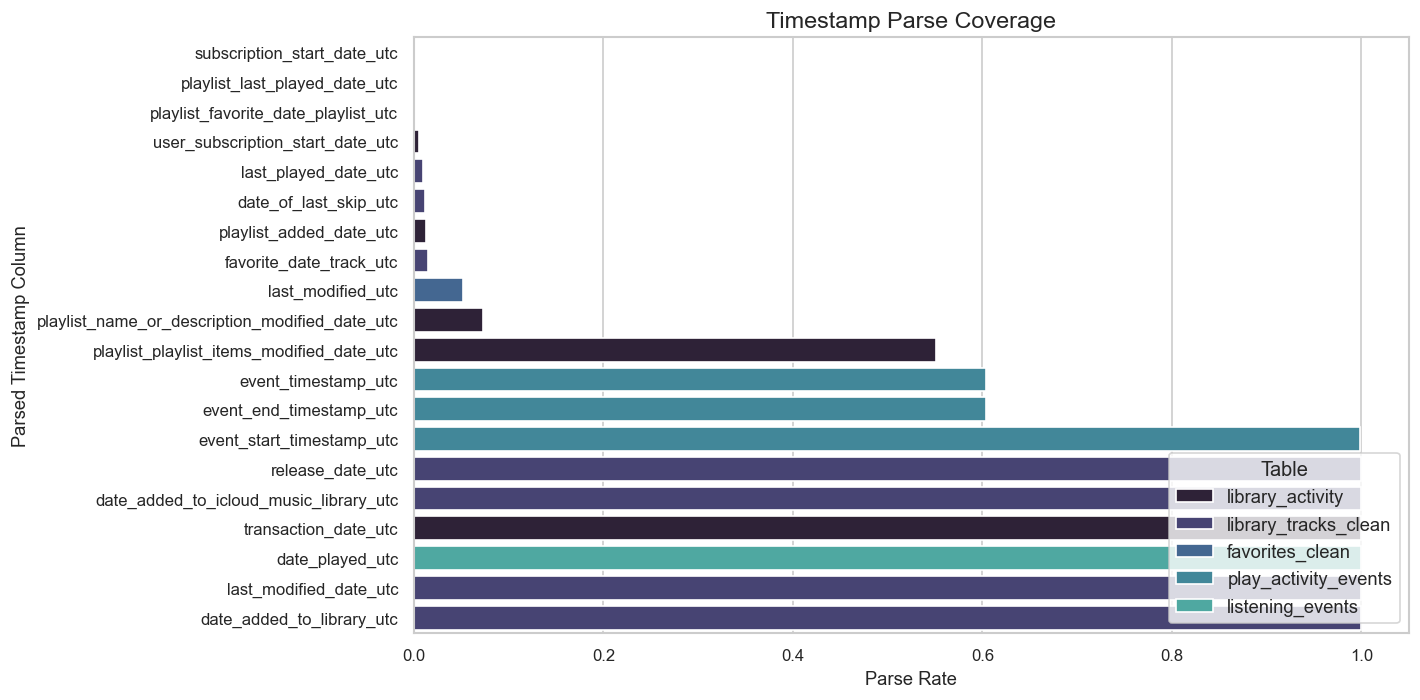

Saved Figure: /Users/Sumaitat/Documents/Coding/music-analytics/reports/figures/exploratory_data_analysis/time_coverage_summary.png


,metric_name,definition,threshold
0,completion_rate,Valid play duration divided by valid media dur...,No threshold
1,very_short_play,Play duration is below the very-short threshold.,10 seconds
2,short_play,Play duration is below the short-play threshold.,30 seconds
3,meaningful_play,Play duration reaches the meaningful-play thre...,30 seconds or 80% completion
4,near_complete_play,Completion rate reaches the near-complete thre...,80% completion
5,started_midtrack,Start position is greater than the mid-track t...,30 seconds
6,possible_seek,Start or end position suggests a non-linear pl...,5 second tolerance
7,skip_like_end,The play is short and not near complete.,Below 30 seconds and below 80% completion


,metric_name,metric_value
0,rows,"22,872.000"
1,valid_play_duration_rows,"13,820.000"
2,valid_media_duration_rows,"22,870.000"
3,completion_invalid_rows,6.000
4,very_short_play_rate,0.360
5,short_play_rate,0.414
6,meaningful_play_rate,0.190
7,near_complete_rate,0.124
8,skip_like_rate,0.414
9,unknown_end_behavior_rate,0.396


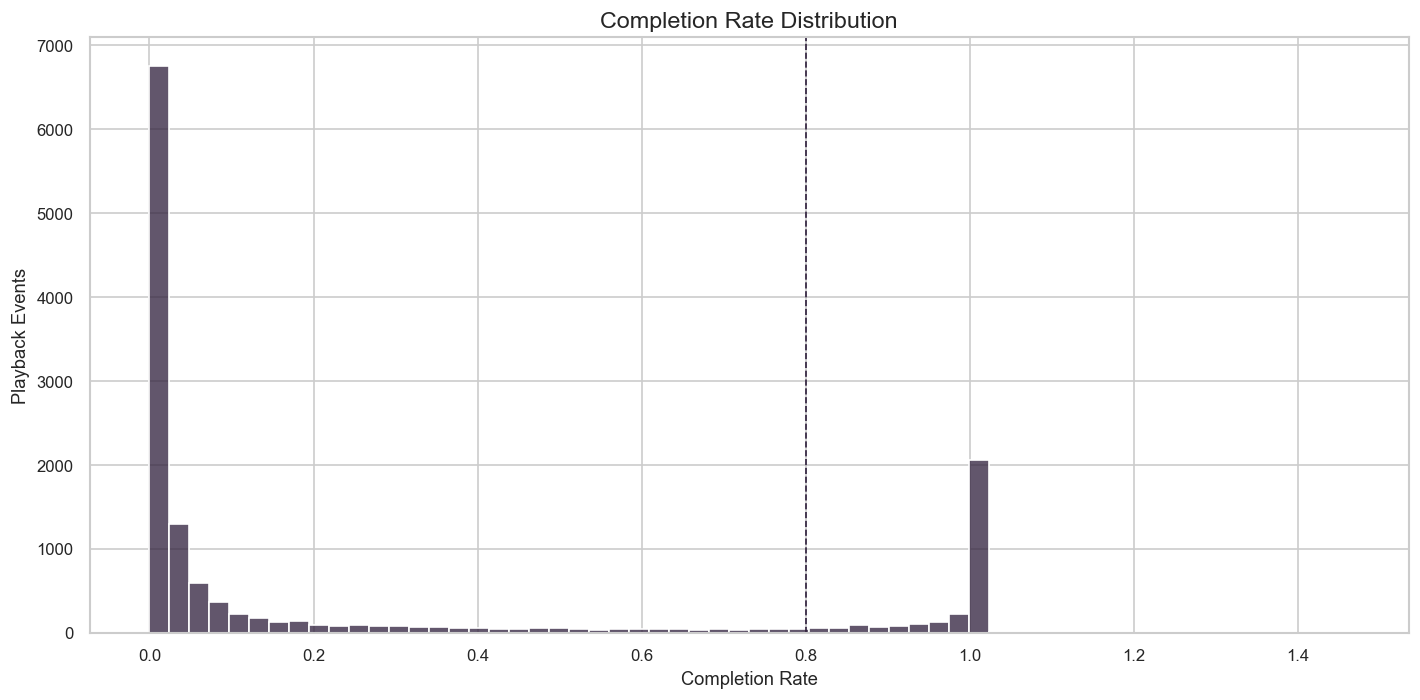

Saved Figure: /Users/Sumaitat/Documents/Coding/music-analytics/reports/figures/exploratory_data_analysis/completion_rate_distribution.png


,gap_minutes,session_count,events_per_session
0,15,543,42.122
1,30,491,46.582
2,60,431,53.067


,session_id,session_start,session_end,event_count,unique_track_count,total_minutes,average_completion,short_play_rate,skip_like_rate,unique_artist_count,dominant_source_context,dominant_device_context,session_duration_minutes,session_date,session_hour
0,session_000001,2025-10-18 00:35:42.590000+00:00,2025-10-18 00:35:43.262000+00:00,4,2,0.023,0.006,0.500,0.500,NaN,library / songs,IPHONE,0.011,2025-10-18,0.000
1,session_000002,2025-10-18 05:41:57.970000+00:00,2025-10-18 06:07:19.081000+00:00,52,18,8.749,0.088,0.385,0.385,NaN,library / playlists / playlist_detail,IPHONE,25.352,2025-10-18,5.000
2,session_000003,2025-10-18 15:02:52.342000+00:00,2025-10-18 15:08:10.165000+00:00,5,2,1.540,0.227,0.400,0.400,NaN,library / playlists / playlist_detail,IPHONE,5.297,2025-10-18,15.000
3,session_000004,2025-10-18 18:43:49.508000+00:00,2025-10-18 18:46:10.402000+00:00,5,2,0.127,0.011,0.600,0.600,NaN,home / playlist_detail,IPHONE,2.348,2025-10-18,18.000
4,session_000005,2025-10-18 21:11:00.015000+00:00,2025-10-18 21:11:29.579000+00:00,49,25,0.189,0.002,0.490,0.490,NaN,home / grouping,IPHONE,0.493,2025-10-18,21.000


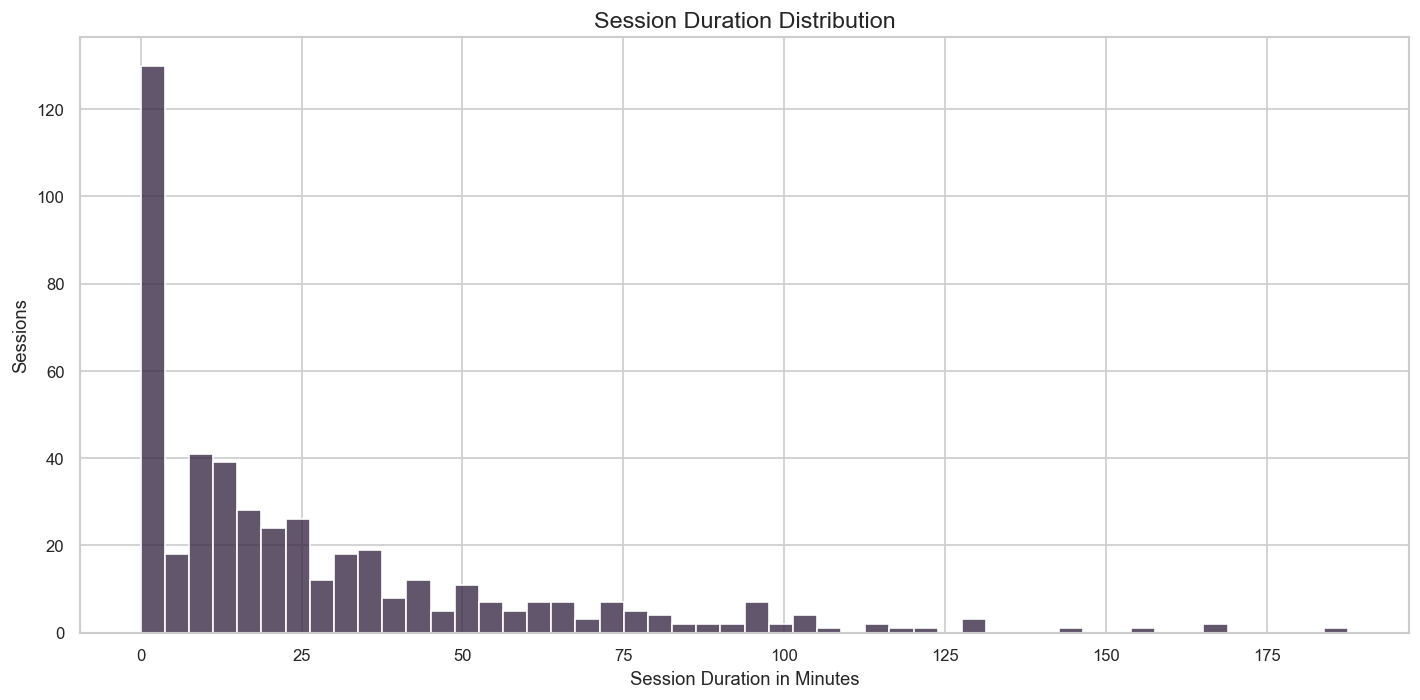

Saved Figure: /Users/Sumaitat/Documents/Coding/music-analytics/reports/figures/exploratory_data_analysis/session_duration_distribution.png


,raw_source_context,source_context,row_count
36,library / playlist_detail,library,6345
56,now_playing,other,3491
40,library / playlist_details,library,2953
42,library / playlists / playlist_folder / playli...,library,1346
3,MusicKit,other,1113
41,library / playlists / playlist_detail,library,980
58,search / album_detail,album,881
16,home / playlist_detail,playlist,653
48,new / album_detail,album,525
21,library,library,395


,raw_device_context,device_context,row_count
1,IPHONE,mobile,13501
2,MACINTOSH,desktop,7579
3,WINDOWS,desktop,1138
0,ANDROID,other,654


,join_name,left_table,right_table,left_column,right_column,status,left_row_count,right_row_count,matched_rows,match_rate,left_unique_values,right_unique_values
0,container_details_to_origin,container_details,container_origin,container_description,artist_name,Tested,162,69,0,0.000,74,0
1,container_details_to_playlists,container_details,library_playlists,container_description,title,Tested,162,144,32,0.198,74,132
2,container_origin_to_playlists,container_origin,library_playlists,artist_name,title,Tested,69,144,0,0.000,0,132


,total_listening_minutes,active_days,total_playback_events,unique_tracks,unique_artists,average_minutes_per_active_day,short_play_rate,skip_like_rate,average_completion_rate
0,"11,465.398",144,22872,3047,0,79.621,0.414,0.414,0.263


,local_date,listening_minutes,playback_events,unique_tracks,average_completion,short_play_rate,skip_like_rate
0,2025-10-18,10.628,115,49,0.053,0.443,0.443
1,2025-10-19,0.123,7,2,0.006,0.714,0.714
2,2025-10-20,69.581,141,56,0.307,0.298,0.298
3,2025-10-21,55.648,140,60,0.194,0.336,0.336
4,2025-10-22,197.590,812,202,0.106,0.613,0.612


,local_hour,listening_minutes,playback_events,average_completion,short_play_rate
0,0.000,963.751,1788,0.277,0.388
1,1.000,"1,128.923",2272,0.275,0.386
2,2.000,733.169,1735,0.212,0.482
3,3.000,823.045,1515,0.272,0.423
4,4.000,871.330,1137,0.388,0.333
5,5.000,626.942,1376,0.213,0.458
6,6.000,524.177,908,0.245,0.469
7,7.000,368.807,592,0.309,0.412
8,8.000,87.590,208,0.234,0.399
9,9.000,105.942,197,0.489,0.264


,local_day_number,local_day_name,listening_minutes,playback_events,average_completion,short_play_rate
0,0.000,Monday,"1,348.452",2736,0.254,0.407
1,1.000,Tuesday,"1,795.772",3726,0.244,0.439
2,2.000,Wednesday,"1,841.210",3819,0.262,0.421
3,3.000,Thursday,"2,336.118",3602,0.319,0.385
4,4.000,Friday,"1,177.803",2949,0.216,0.458
5,5.000,Saturday,"1,294.810",2960,0.251,0.389
6,6.000,Sunday,"1,663.405",3058,0.286,0.396


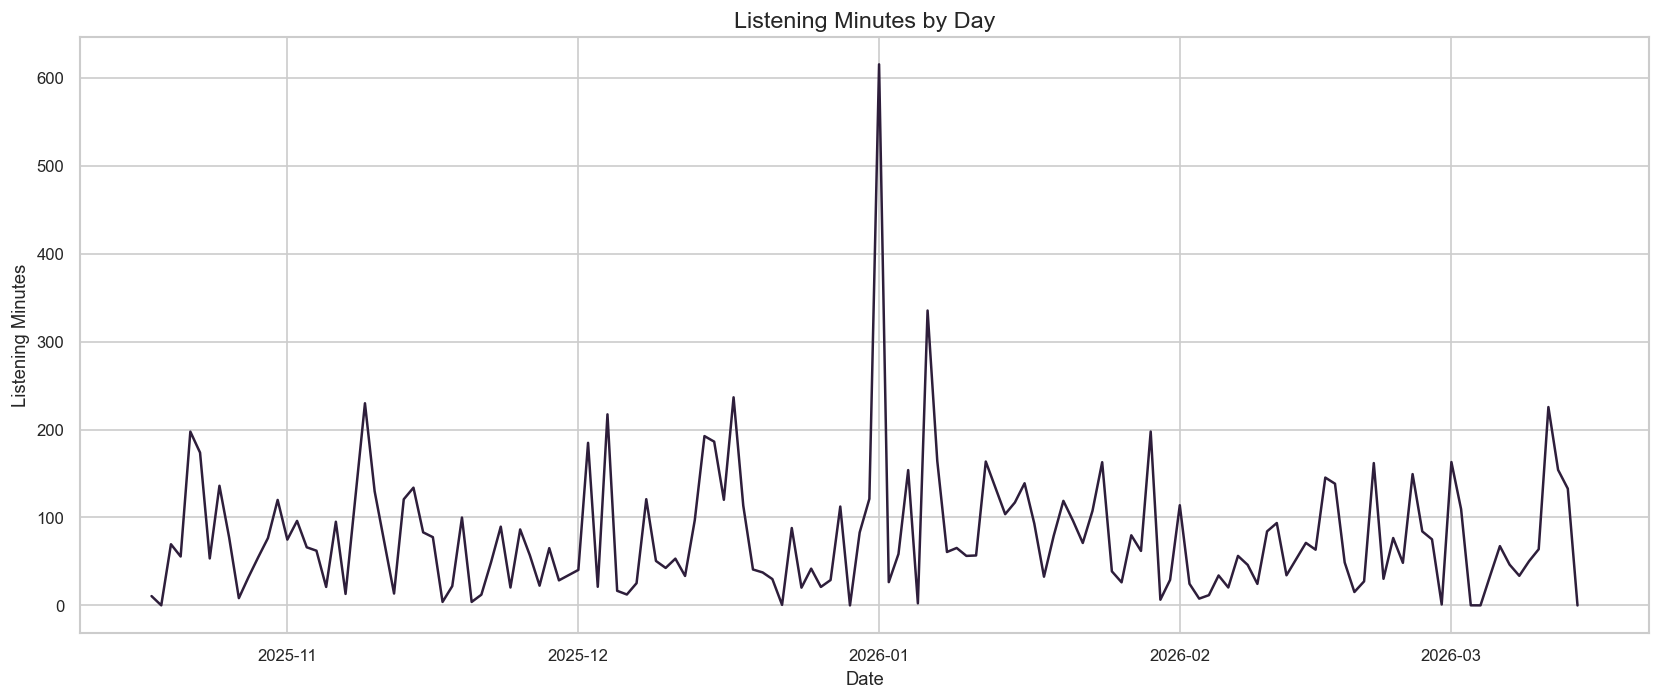

Saved Figure: /Users/Sumaitat/Documents/Coding/music-analytics/reports/figures/exploratory_data_analysis/listening_minutes_by_day.png


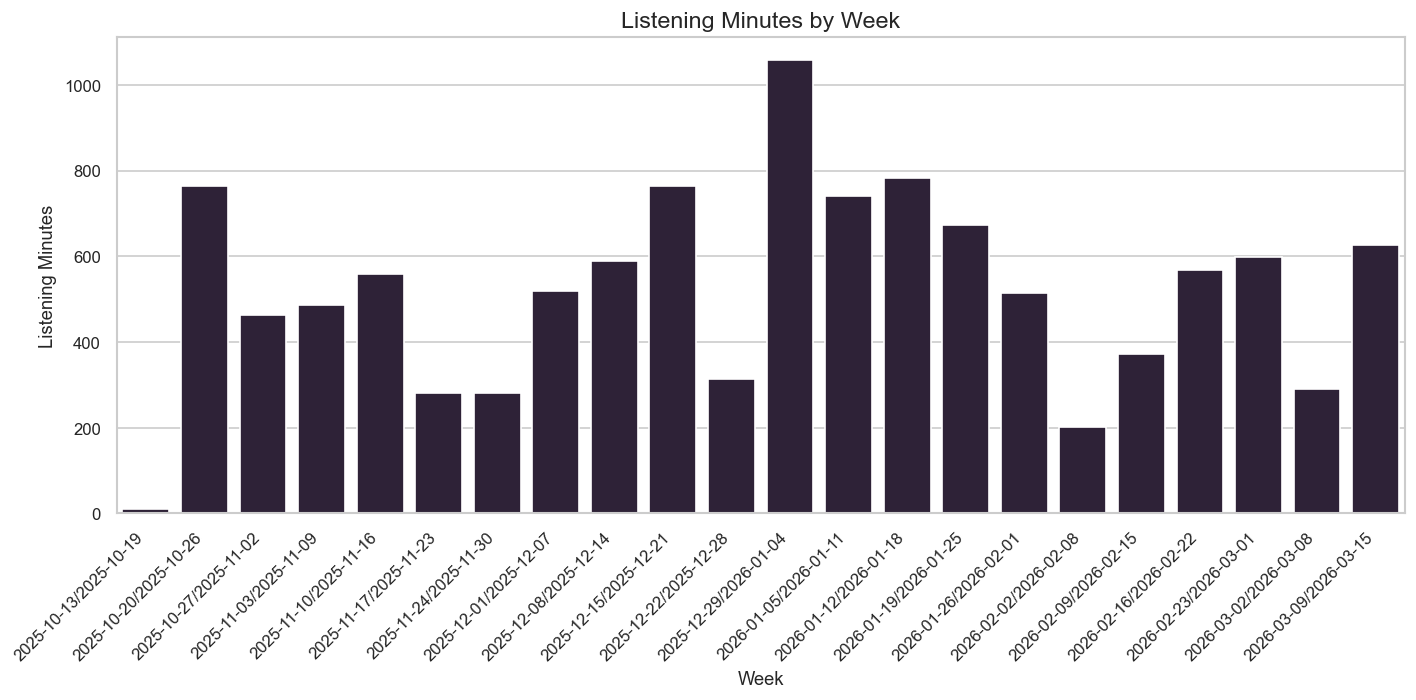

Saved Figure: /Users/Sumaitat/Documents/Coding/music-analytics/reports/figures/exploratory_data_analysis/listening_minutes_by_week.png


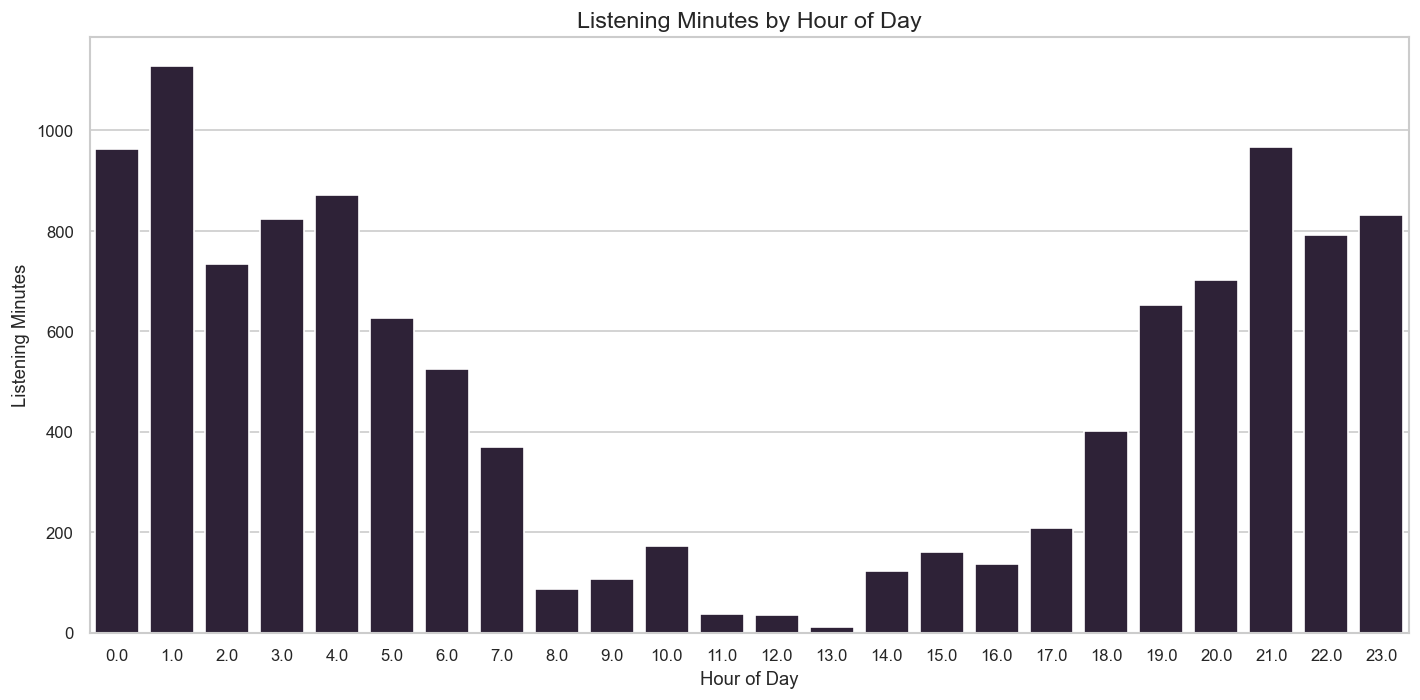

Saved Figure: /Users/Sumaitat/Documents/Coding/music-analytics/reports/figures/exploratory_data_analysis/listening_minutes_by_hour.png


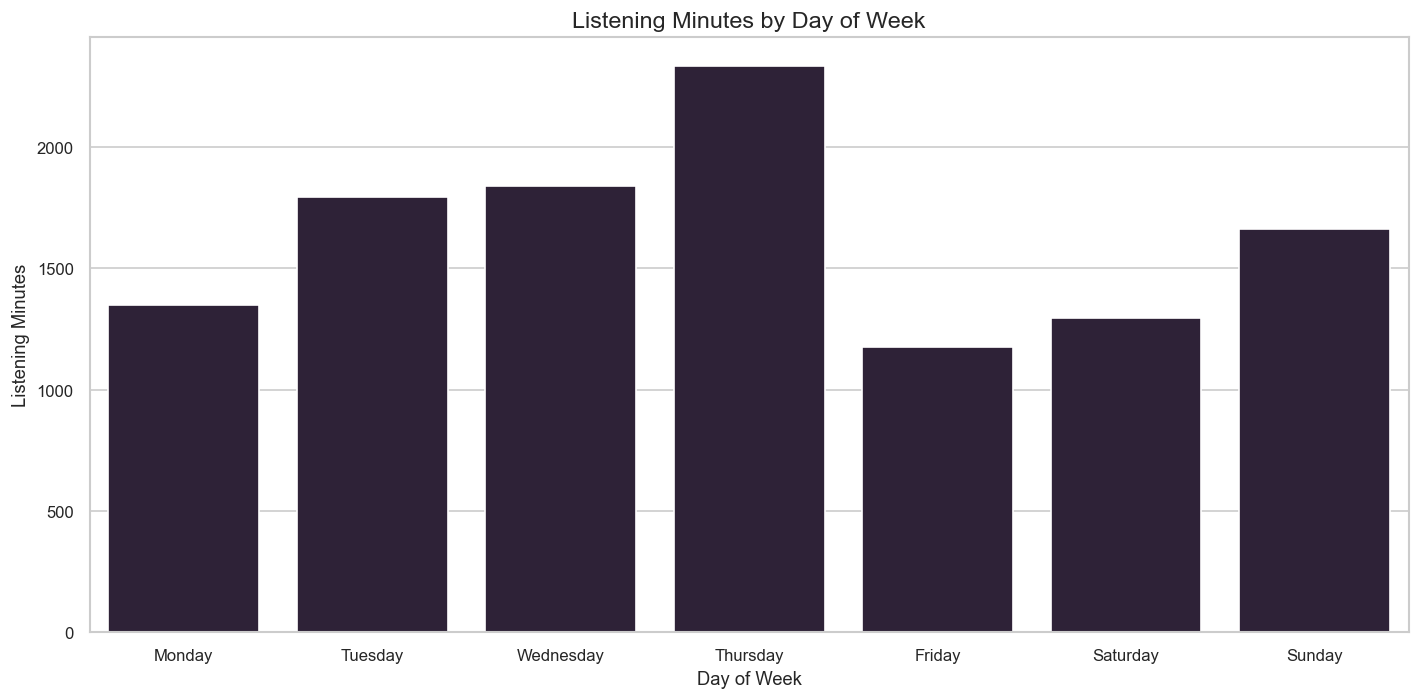

Saved Figure: /Users/Sumaitat/Documents/Coding/music-analytics/reports/figures/exploratory_data_analysis/listening_minutes_by_day_of_week.png


,source_context,rows,listening_minutes,mean_completion,median_completion,short_play_rate,meaningful_play_rate,near_complete_rate,skip_like_rate
2,library,13202,"7,443.635",0.321,0.030,0.335,0.204,0.142,0.335
3,other,5063,"1,807.184",0.163,0.025,0.627,0.160,0.082,0.627
0,album,2675,"1,434.922",0.274,0.023,0.417,0.193,0.137,0.416
4,playlist,1265,440.959,0.193,0.015,0.421,0.153,0.075,0.421
6,search,612,317.842,0.307,0.048,0.333,0.224,0.137,0.333
1,artist_page,53,20.843,0.195,0.038,0.396,0.170,0.075,0.396
5,radio_like,2,0.013,0.000,0.000,0.500,0.000,0.000,0.500


,device_context,rows,listening_minutes,mean_completion,median_completion,short_play_rate,meaningful_play_rate,near_complete_rate,skip_like_rate
1,mobile,13501,"6,137.630",0.263,0.023,0.391,0.180,0.116,0.391
0,desktop,8717,"5,134.439",0.272,0.034,0.437,0.214,0.141,0.437
2,other,654,193.329,0.135,0.003,0.572,0.102,0.073,0.572


,track_key,playback_events,listening_minutes,mean_completion,median_completion,short_play_rate,meaningful_play_rate,skip_like_rate,track_title,artist_name,genre
0,title_artist:back 2 u am 0127,2,0.005,0.001,0.001,1.000,0.000,1.000,NaN,NaN,NaN
1,title_artist:cupid twin ver feat sabrina carp...,2,0.015,0.003,0.003,1.000,0.000,1.000,NaN,NaN,NaN
2,title_artist:hypnosis,2,0.008,0.002,0.002,1.000,0.000,1.000,NaN,NaN,NaN
3,title_artist:kingdom come,2,0.001,0.000,0.000,1.000,0.000,1.000,NaN,NaN,NaN
4,title_artist:red flavor,2,0.004,0.001,0.001,1.000,0.000,1.000,NaN,NaN,NaN
5,title_artist:shake it,2,0.007,0.001,0.001,1.000,0.000,1.000,NaN,NaN,NaN
6,title_artist:teri meri,2,0.021,0.002,0.002,1.000,0.000,1.000,NaN,NaN,NaN
7,title_artist:tko,2,0.021,0.003,0.003,1.000,0.000,1.000,NaN,NaN,NaN
8,title_artist:vogue chant intro,2,0.134,0.067,0.067,1.000,0.000,1.000,NaN,NaN,NaN
9,title_artist:punk rocky,10,0.414,0.012,0.006,0.900,0.000,0.900,NaN,NaN,NaN


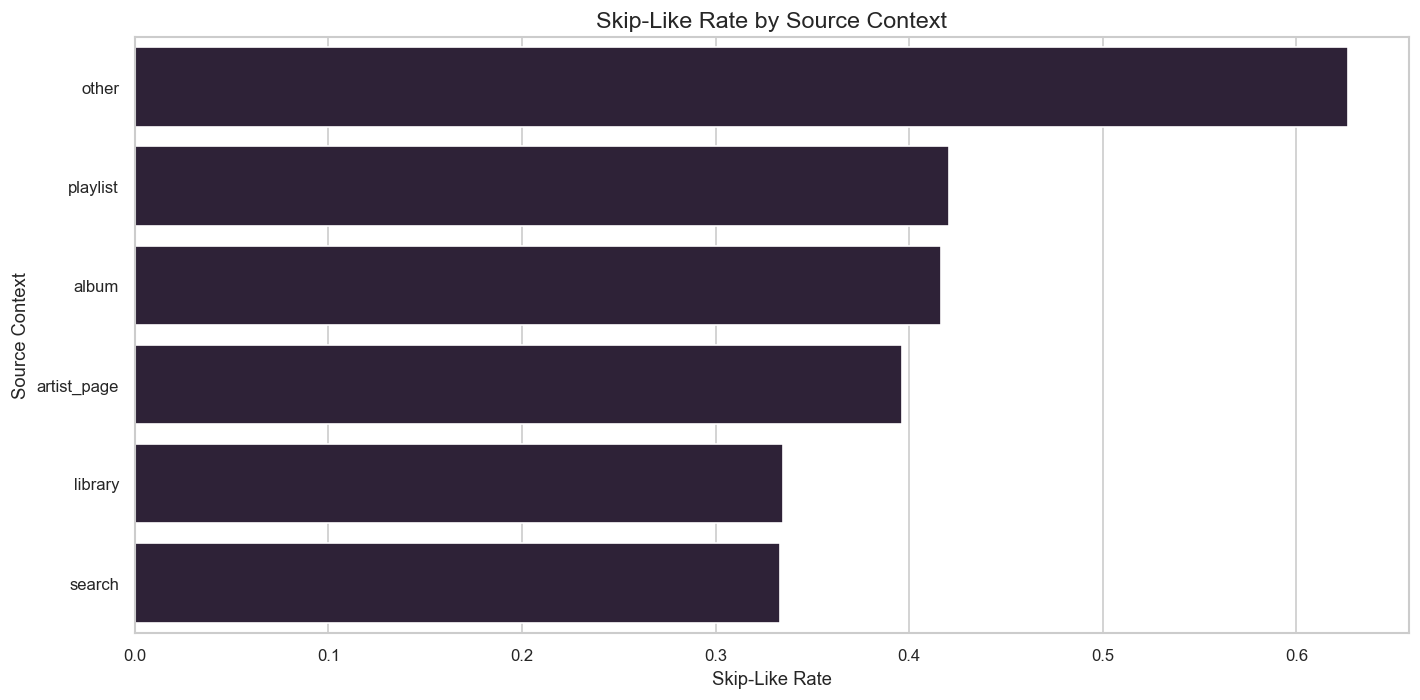

Saved Figure: /Users/Sumaitat/Documents/Coding/music-analytics/reports/figures/exploratory_data_analysis/friction_by_source_context.png


,track_key,first_observed,last_observed,playback_events,total_minutes,active_days,mean_completion,short_play_rate,skip_like_rate,meaningful_plays,days_since_first,days_since_last,repeat_track,discovery_status,track_title,artist_name,album_title,genre,track_duration_minutes,preference_state,favorite_records
0,title_artist:'round midnight,2025-10-21 15:47:03.345000+00:00,2025-10-21 15:47:03.496000+00:00,2,0.019,1,0.003,0.500,0.500,0,144.000,144.000,True,dormant_return,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,title_artist:'till i collapse feat nate dogg,2025-10-22 14:52:39.602000+00:00,2025-10-22 14:52:39.606000+00:00,2,0.031,1,0.006,0.500,0.500,0,143.000,143.000,True,dormant_return,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,title_artist:1,2025-10-23 19:08:26.869000+00:00,2025-11-09 01:10:31.236000+00:00,4,0.075,2,0.005,0.500,0.500,0,142.000,125.000,True,dormant_return,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,title_artist:1 shot,2025-10-22 02:15:25.962000+00:00,2026-02-05 21:46:48.031000+00:00,29,8.156,8,0.170,0.552,0.552,4,143.000,36.000,True,loyal,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,title_artist:1-800-hot-n-fun,2025-11-09 19:49:45.841000+00:00,2026-03-11 00:49:41.746000+00:00,4,1.149,2,0.199,0.250,0.250,1,125.000,3.000,True,returning,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,discovery_status,track_count,total_minutes,median_events,repeat_rate,mean_completion,short_play_rate,preference_record_rate
0,dormant_return,1802,"1,949.632",3.000,1.000,0.152,0.494,0.000
3,returning,882,"7,611.410",6.000,1.000,0.166,0.464,0.000
1,loyal,180,"1,831.575",12.000,1.000,0.269,0.405,0.000
2,newly_observed,96,0.892,1.000,0.000,0.004,0.688,0.000
4,unresolved,87,71.889,2.000,1.000,0.097,0.489,0.000


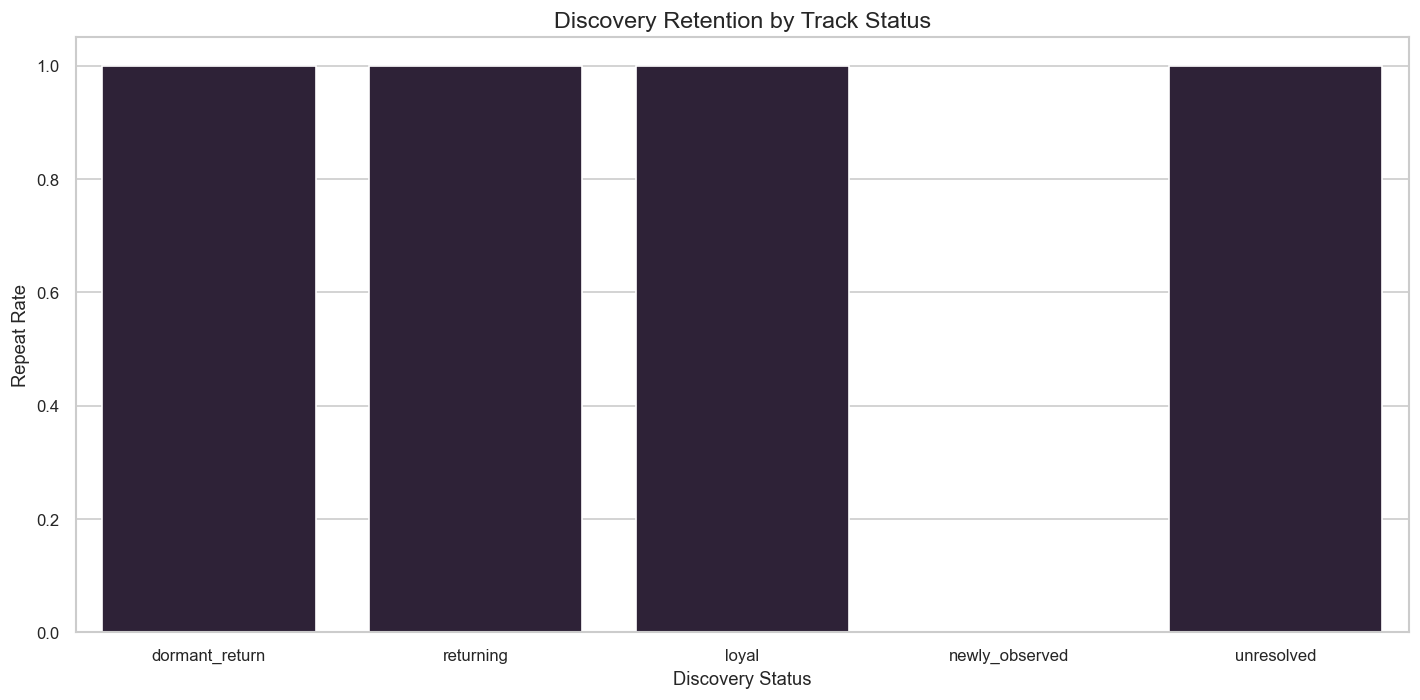

Saved Figure: /Users/Sumaitat/Documents/Coding/music-analytics/reports/figures/exploratory_data_analysis/discovery_retention_summary.png


,dimension,item_count,total_minutes,top_one_share,top_five_share,top_ten_share,long_tail_share_after_top_ten,hhi,entropy
0,track,3047,"11,465.398",0.032,0.106,0.168,0.832,0.006,8.821
1,artist,1,"11,465.398",1.000,1.000,1.000,0.000,1.000,-0.000
2,album,1,"11,465.398",1.000,1.000,1.000,0.000,1.000,-0.000
3,genre,1,"11,465.398",1.000,1.000,1.000,0.000,1.000,-0.000


,local_date,unique_tracks,unique_artists,listening_minutes
0,2025-10-18,49,0,10.628
1,2025-10-19,2,0,0.123
2,2025-10-20,56,0,69.581
3,2025-10-21,60,0,55.648
4,2025-10-22,202,0,197.590


,session_id,unique_track_count,unique_artist_count,total_minutes
0,session_000001,2,NaN,0.023
1,session_000002,18,NaN,8.749
2,session_000003,2,NaN,1.540
3,session_000004,2,NaN,0.127
4,session_000005,25,NaN,0.189


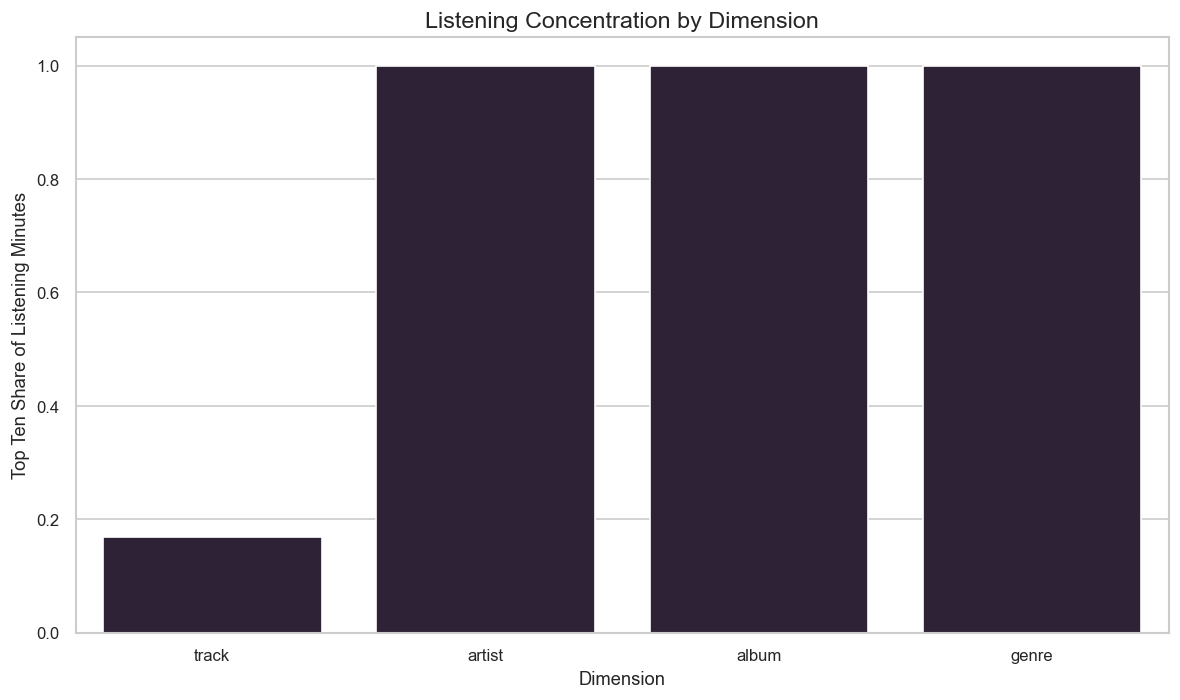

Saved Figure: /Users/Sumaitat/Documents/Coding/music-analytics/reports/figures/exploratory_data_analysis/listening_concentration_summary.png


,library_flag,favorite_flag,preference_state,track_count,total_minutes,median_events,mean_completion,short_play_rate,skip_like_rate
0,False,False,neutral_or_unknown,3047,"11,465.398",3.000,0.158,0.486,0.486


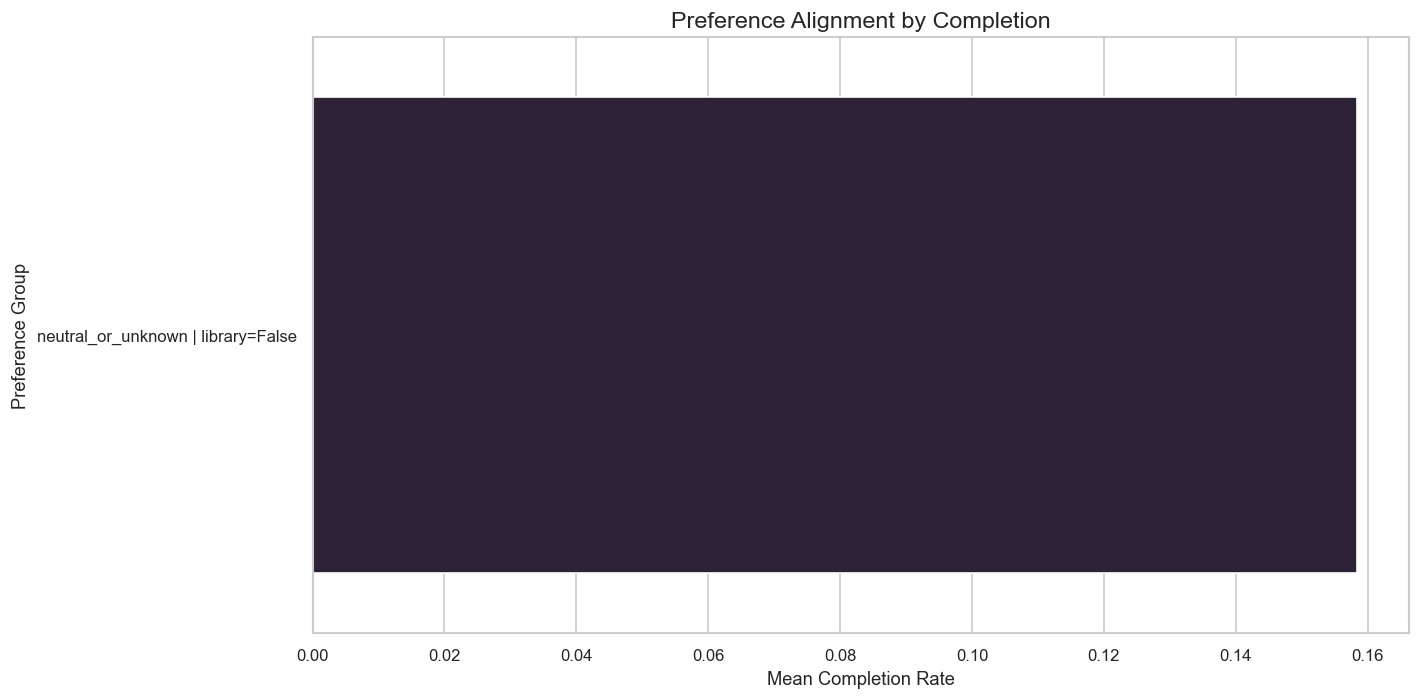

Saved Figure: /Users/Sumaitat/Documents/Coding/music-analytics/reports/figures/exploratory_data_analysis/preference_alignment_by_completion.png


,source_context,playback_events,listening_minutes,unique_tracks,mean_completion,median_completion,short_play_rate,meaningful_play_rate,skip_like_rate
2,library,13202,"7,443.635",2089,0.321,0.030,0.335,0.204,0.335
3,other,5063,"1,807.184",1800,0.163,0.025,0.627,0.160,0.627
0,album,2675,"1,434.922",576,0.274,0.023,0.417,0.193,0.416
4,playlist,1265,440.959,387,0.193,0.015,0.421,0.153,0.421
6,search,612,317.842,149,0.307,0.048,0.333,0.224,0.333
1,artist_page,53,20.843,20,0.195,0.038,0.396,0.170,0.396
5,radio_like,2,0.013,2,0.000,0.000,0.500,0.000,0.500


,container_type,playback_events,listening_minutes,unique_tracks,mean_completion,short_play_rate,skip_like_rate
2,PLAYLIST,14590,"7,639.131",2183,0.269,0.403,0.403
0,ALBUM,3902,"2,110.925",686,0.253,0.462,0.462
5,UNKNOWN,2945,"1,149.831",437,0.265,0.405,0.405
4,RADIO,1062,297.574,363,0.160,0.454,0.454
3,PLAYLIST_FOLDER,334,251.909,93,0.430,0.266,0.266


In [4]:
# %% [markdown]
# # Music Streaming Behavior Analytics
#
# ## Exploratory Data Analysis
#
# This notebook validates analytical assumptions, defines behavioral metrics, tests enrichment joins, creates dashboard-ready analytical datasets, and prepares recommender-ready features. It starts from the completed data-check outputs instead of rediscovering the project files from scratch.

# %%
%matplotlib inline

import json
import re
import sys
import warnings

from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")


# %%
pd.set_option("display.max_columns", 180)
pd.set_option("display.width", 220)
pd.set_option("display.max_rows", 120)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

sns.set_theme(
    context="notebook",
    style="whitegrid",
    palette="mako",
)

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["xtick.labelsize"] = 10
plt.rcParams["ytick.labelsize"] = 10


# %% [markdown]
# ## 1. Project Setup
#
# This section locates the project root, defines the EDA output folders, and prepares reusable project paths.

# %%
root = Path.cwd()

for path in [Path.cwd(), *Path.cwd().parents]:
    if (path / "data").exists() and (path / "requirements.txt").exists():
        root = path
        break

if root.name != "music-analytics":
    fallback = Path.home() / "Documents" / "Coding" / "music-analytics"

    if fallback.exists():
        root = fallback

sys.path.insert(0, str(root))

data_root = root / "data"
processed_root = data_root / "processed"
analytics_root = processed_root / "analytics"

reports_root = root / "reports"
check_tables_root = reports_root / "tables" / "data_check"
eda_tables_root = reports_root / "tables" / "exploratory_data_analysis"
eda_figures_root = reports_root / "figures" / "exploratory_data_analysis"

analytics_root.mkdir(parents=True, exist_ok=True)
eda_tables_root.mkdir(parents=True, exist_ok=True)
eda_figures_root.mkdir(parents=True, exist_ok=True)

print("Project Root:", root)
print("Data Check Tables Directory Exists:", check_tables_root.exists())
print("EDA Tables Directory:", eda_tables_root)
print("EDA Figures Directory:", eda_figures_root)
print("Analytics Directory:", analytics_root)


# %% [markdown]
# ## 2. Helper Functions
#
# These functions keep the notebook readable and prevent repeated logic across table loading, date parsing, joining, validation, metric creation, and output saving.

# %%
def clean_name(value: Any) -> str:
    value = str(value).strip().lower()
    value = re.sub(r"[^a-z0-9]+", "_", value)
    value = re.sub(r"_+", "_", value)
    return value.strip("_")


def clean_columns(dataframe: pd.DataFrame) -> pd.DataFrame:
    output = dataframe.copy()
    output.columns = [clean_name(column) for column in output.columns]
    return output


def neutral_name(value: Any) -> str:
    name = clean_name(value)
    name = name.replace("apple_music_track_identifier", "catalog_track_id")
    name = name.replace("apple_music", "catalog")
    return name


def neutral_columns(dataframe: pd.DataFrame) -> pd.DataFrame:
    output = dataframe.copy()
    output.columns = [neutral_name(column) for column in output.columns]
    return output


def save_table(dataframe: pd.DataFrame, file_name: str) -> Path:
    output = eda_tables_root / file_name
    dataframe.to_csv(output, index=False)
    return output


def save_json(data: dict, file_name: str) -> Path:
    output = eda_tables_root / file_name

    with open(output, "w", encoding="utf-8") as file:
        json.dump(data, file, indent=4, default=str)

    return output


def save_figure(file_name: str) -> Path:
    output = eda_figures_root / file_name
    plt.savefig(output, dpi=200, bbox_inches="tight")
    return output


def save_parquet(dataframe: pd.DataFrame, file_name: str) -> Path:
    output = analytics_root / file_name
    dataframe.to_parquet(output, index=False)
    return output


def read_table(path: Path) -> pd.DataFrame:
    if path.name.endswith(".parquet"):
        return pd.read_parquet(path)

    if path.name.endswith(".csv"):
        return pd.read_csv(path, low_memory=False)

    raise ValueError(f"Unsupported File Type: {path}")


def read_csv_artifact(file_name: str) -> pd.DataFrame:
    path = check_tables_root / file_name

    if not path.exists():
        return pd.DataFrame()

    return pd.read_csv(path, low_memory=False)


def read_json_artifact(file_name: str) -> dict:
    path = check_tables_root / file_name

    if not path.exists():
        return {}

    with open(path, "r", encoding="utf-8") as file:
        return json.load(file)


def find_col(dataframe: pd.DataFrame, candidates: list[str]) -> str | None:
    lookup = {clean_name(column): column for column in dataframe.columns}

    for candidate in candidates:
        clean_candidate = clean_name(candidate)

        if clean_candidate in lookup:
            return lookup[clean_candidate]

    return None


def find_cols(dataframe: pd.DataFrame, candidates: list[str]) -> list[str]:
    columns = []

    for candidate in candidates:
        column = find_col(dataframe, [candidate])

        if column is not None:
            columns.append(column)

    return columns


def first_col(dataframe: pd.DataFrame, terms: list[str]) -> str | None:
    for column in dataframe.columns:
        clean_column = clean_name(column)

        if any(term in clean_column for term in terms):
            return column

    return None


def parse_datetime(series: pd.Series) -> pd.Series:
    if pd.api.types.is_datetime64_any_dtype(series):
        return pd.to_datetime(series, errors="coerce", utc=True)

    values = series.copy()

    if pd.api.types.is_numeric_dtype(values):
        numeric = pd.to_numeric(values, errors="coerce")
        non_null = numeric.dropna()

        if non_null.empty:
            return pd.to_datetime(values, errors="coerce", utc=True)

        median_value = non_null.abs().median()

        if median_value >= 1_000_000_000_000:
            return pd.to_datetime(numeric, errors="coerce", unit="ms", utc=True)

        if median_value >= 10_000_000 and median_value <= 99_999_999:
            text = numeric.astype("Int64").astype(str)
            return pd.to_datetime(text, errors="coerce", format="%Y%m%d", utc=True)

        return pd.to_datetime(values, errors="coerce", utc=True)

    text = (
        values
        .astype(str)
        .str.strip()
        .str.replace(r"\[UTC\]$", "", regex=True)
        .replace(["", "nan", "NaT", "None"], np.nan)
    )

    parsed = pd.to_datetime(text, errors="coerce", utc=True)

    if parsed.notna().mean() == 0:
        parsed = pd.to_datetime(text, errors="coerce", format="%Y%m%d", utc=True)

    return parsed


def add_time_parts(dataframe: pd.DataFrame, timestamp_col: str, prefix: str) -> pd.DataFrame:
    output = dataframe.copy()
    values = pd.to_datetime(output[timestamp_col], errors="coerce", utc=True)

    output[f"{prefix}_date"] = values.dt.date
    output[f"{prefix}_hour"] = values.dt.hour
    output[f"{prefix}_day_name"] = values.dt.day_name()
    output[f"{prefix}_day_number"] = values.dt.dayofweek
    output[f"{prefix}_week"] = values.dt.to_period("W").astype(str)
    output[f"{prefix}_month"] = values.dt.to_period("M").astype(str)
    output[f"{prefix}_year"] = values.dt.year
    output[f"{prefix}_is_weekend"] = values.dt.dayofweek.isin([5, 6])

    return output


def local_timestamp(dataframe: pd.DataFrame, timestamp_col: str, offset_col: str | None = None) -> pd.Series:
    timestamp = pd.to_datetime(dataframe[timestamp_col], errors="coerce", utc=True)

    if offset_col is None or offset_col not in dataframe.columns:
        return timestamp

    offset = pd.to_numeric(dataframe[offset_col], errors="coerce").fillna(0)
    return timestamp + pd.to_timedelta(offset, unit="s")


def normalize_text(value: Any) -> str | None:
    if pd.isna(value):
        return None

    text = str(value).strip().lower()

    if not text:
        return None

    text = re.sub(r"\s+", " ", text)
    text = re.sub(r"[^\w\s\-&']", "", text)
    return text.strip()


def normalize_join(value: Any) -> str | None:
    if pd.isna(value):
        return None

    text = str(value).strip()

    if not text:
        return None

    if re.fullmatch(r"\d+\.0", text):
        text = text[:-2]

    return text.lower()


def numeric(series: pd.Series) -> pd.Series:
    return pd.to_numeric(series, errors="coerce")


def safe_divide(numerator: pd.Series, denominator: pd.Series) -> pd.Series:
    numerator = pd.to_numeric(numerator, errors="coerce")
    denominator = pd.to_numeric(denominator, errors="coerce")

    return np.where(denominator > 0, numerator / denominator, np.nan)


def make_key(dataframe: pd.DataFrame, columns: list[str]) -> pd.Series:
    if len(columns) == 0:
        return pd.Series([None] * len(dataframe), index=dataframe.index, dtype="object")

    values = dataframe[columns].copy()
    values = values.map(normalize_join)

    if len(columns) == 1:
        return values[columns[0]]

    return values.fillna("").astype(str).agg(" || ".join, axis=1).replace("", np.nan)


def text_key(dataframe: pd.DataFrame, title_col: str | None, artist_col: str | None) -> pd.Series:
    if title_col is None:
        return pd.Series([None] * len(dataframe), index=dataframe.index, dtype="object")

    title = dataframe[title_col].map(normalize_text)

    if artist_col is None:
        return title

    artist = dataframe[artist_col].map(normalize_text)
    return title.fillna("") + " || " + artist.fillna("")


def missing_summary(dataframe: pd.DataFrame, table_name: str) -> pd.DataFrame:
    rows = []

    for column in dataframe.columns:
        series = dataframe[column]
        row_count = len(dataframe)
        missing_count = int(series.isna().sum())

        rows.append(
            {
                "table_name": table_name,
                "column_name": column,
                "row_count": row_count,
                "missing_count": missing_count,
                "missing_rate": round(missing_count / row_count, 4) if row_count else 0,
                "unique_count": int(series.dropna().astype(str).nunique()),
            }
        )

    return pd.DataFrame(rows)


def hhi(values: pd.Series) -> float:
    shares = values.dropna()
    shares = shares / shares.sum() if shares.sum() else shares
    return float((shares ** 2).sum())


def entropy(values: pd.Series) -> float:
    shares = values.dropna()
    shares = shares / shares.sum() if shares.sum() else shares
    shares = shares[shares > 0]
    return float(-(shares * np.log2(shares)).sum())


def top_share(values: pd.Series, n: int) -> float:
    total = values.sum()

    if total == 0:
        return np.nan

    return float(values.sort_values(ascending=False).head(n).sum() / total)


def summarize_metric(dataframe: pd.DataFrame, group_col: str) -> pd.DataFrame:
    if dataframe.empty or group_col not in dataframe.columns:
        return pd.DataFrame()

    return (
        dataframe
        .groupby(group_col, dropna=False)
        .agg(
            rows=("track_key", "size"),
            listening_minutes=("play_minutes", "sum"),
            mean_completion=("completion_rate", "mean"),
            median_completion=("completion_rate", "median"),
            short_play_rate=("short_play", "mean"),
            meaningful_play_rate=("meaningful_play", "mean"),
            near_complete_rate=("near_complete_play", "mean"),
            skip_like_rate=("skip_like_end", "mean"),
        )
        .reset_index()
        .sort_values("listening_minutes", ascending=False)
    )


# %% [markdown]
# ## 3. Load Data-Check Outputs
#
# The EDA begins from the artifacts created by `00_data_check.ipynb`. These files define the approved table set, table roles, join candidates, readiness scores, column inventories, and source paths.

# %%
contracts = read_csv_artifact("table_contracts.csv")
eda_tables = read_csv_artifact("eda_input_tables.csv")
selected_files = read_csv_artifact("selected_files_for_eda.csv")
check_joins = read_csv_artifact("join_quality_report.csv")
readiness = read_csv_artifact("table_readiness.csv")
check_columns = read_csv_artifact("column_inventory_selected_tables.csv")
date_audit = read_csv_artifact("date_audit_selected_tables.csv")
numeric_audit = read_csv_artifact("numeric_audit_selected_tables.csv")
duration_audit = read_csv_artifact("millisecond_audit_selected_tables.csv")
check_summary = read_json_artifact("data_check_summary.json")

print("Contracts Loaded:", len(contracts))
print("EDA Input Tables Loaded:", len(eda_tables))
print("Selected File Records Loaded:", len(selected_files))
print("Data Check Summary Keys:", list(check_summary.keys()))

display(eda_tables)


# %%
tables = {}
load_rows = []

for _, row in eda_tables.iterrows():
    table_name = row["canonical_name"]
    relative_path = row["relative_path"]
    path = root / relative_path

    try:
        dataframe = read_table(path)
        dataframe = clean_columns(dataframe)

        tables[table_name] = dataframe

        load_rows.append(
            {
                "canonical_name": table_name,
                "relative_path": relative_path,
                "load_status": "Loaded",
                "row_count": dataframe.shape[0],
                "column_count": dataframe.shape[1],
                "expected_row_count": row["row_count"],
                "expected_column_count": row["column_count"],
                "next_use": row["next_use"],
                "project_role": row["project_role"],
                "grain": row["grain"],
                "error_message": "",
            }
        )

    except Exception as error:
        load_rows.append(
            {
                "canonical_name": table_name,
                "relative_path": relative_path,
                "load_status": "Failed",
                "row_count": np.nan,
                "column_count": np.nan,
                "expected_row_count": row["row_count"],
                "expected_column_count": row["column_count"],
                "next_use": row["next_use"],
                "project_role": row["project_role"],
                "grain": row["grain"],
                "error_message": str(error),
            }
        )

loaded = pd.DataFrame(load_rows)

loaded["row_count_match"] = loaded["row_count"] == loaded["expected_row_count"]
loaded["column_count_match"] = loaded["column_count"] == loaded["expected_column_count"]
loaded["contract_status"] = np.where(
    (loaded["load_status"] == "Loaded") & loaded["row_count_match"] & loaded["column_count_match"],
    "Approved",
    "Review",
)

save_table(loaded, "eda_loaded_tables.csv")

print("Loaded Tables:", int((loaded["load_status"] == "Loaded").sum()))
print("Failed Tables:", int((loaded["load_status"] == "Failed").sum()))

display(loaded)


# %% [markdown]
# ## 4. Validate Table Contracts
#
# This section confirms that each selected EDA table still matches the row count, column count, role, and grain declared by the data-check notebook.

# %%
contract_validation = (
    loaded
    .merge(
        contracts[
            [
                "canonical_name",
                "preferred_key",
                "dashboard_use",
                "model_use",
                "reason",
            ]
        ],
        on="canonical_name",
        how="left",
    )
    .sort_values(["next_use", "contract_status", "row_count"], ascending=[True, True, False])
    .reset_index(drop=True)
)

save_table(contract_validation, "eda_table_contract_validation.csv")

display(contract_validation)


# %%
approved_core = contract_validation.query("next_use == 'EDA Core' and contract_status == 'Approved'")["canonical_name"].tolist()
approved_support = contract_validation.query("next_use == 'EDA Support' and contract_status == 'Approved'")["canonical_name"].tolist()
approved_validation = contract_validation.query("next_use == 'Validation Only' and contract_status == 'Approved'")["canonical_name"].tolist()
contract_risks = contract_validation.query("contract_status != 'Approved'")["canonical_name"].tolist()

print("Approved Core EDA Tables:", approved_core)
print("Approved Support EDA Tables:", approved_support)
print("Approved Validation Tables:", approved_validation)
print("Contract Risks:", contract_risks)


# %% [markdown]
# ### Contract Interpretation
#
# The approved core tables are the default analytical sources for playback behavior, summarized listening behavior, track metadata, and explicit preferences. Support tables can enrich context, identity resolution, playlist structure, source context, recent activity, and validation checks. Validation-only tables should be used to compare aggregate totals, not to drive primary metrics. Raw fallback tables should not be used directly unless a required field is absent from the processed behavioral tables.

# %% [markdown]
# ## 5. Grain Validation
#
# Correct grain is more important than table size. This section checks whether each table behaves like an event table, summary table, metadata dimension, preference table, support table, or validation table.

# %%
def grain_test(dataframe: pd.DataFrame, table_name: str, candidates: list[list[str]]) -> pd.DataFrame:
    rows = []

    for candidate in candidates:
        columns = find_cols(dataframe, candidate)

        if len(columns) != len(candidate):
            rows.append(
                {
                    "table_name": table_name,
                    "candidate_columns": " | ".join(candidate),
                    "resolved_columns": " | ".join(columns),
                    "status": "Missing Column",
                    "row_count": len(dataframe),
                    "unique_keys": np.nan,
                    "duplicate_rows": np.nan,
                    "unique_rate": np.nan,
                }
            )

            continue

        key_values = make_key(dataframe, columns)
        unique_keys = int(key_values.dropna().nunique())
        duplicate_rows = int(key_values.duplicated(keep=False).sum())

        rows.append(
            {
                "table_name": table_name,
                "candidate_columns": " | ".join(candidate),
                "resolved_columns": " | ".join(columns),
                "status": "Tested",
                "row_count": len(dataframe),
                "unique_keys": unique_keys,
                "duplicate_rows": duplicate_rows,
                "unique_rate": round(unique_keys / len(dataframe), 4) if len(dataframe) else 0,
            }
        )

    return pd.DataFrame(rows)


grain_rows = []

if "play_activity_events" in tables:
    activity = tables["play_activity_events"]

    activity_candidates = [
        ["event_identifier"],
        ["event_id"],
        ["transaction_identifier"],
        ["event_start_timestamp", "event_end_timestamp", "song_name", "media_duration_in_milliseconds"],
        ["event_start_timestamp", "song_name", "source_type", "media_duration_in_milliseconds"],
        ["event_start_timestamp", "song_name", "play_duration_milliseconds"],
    ]

    grain_rows.append(grain_test(activity, "play_activity_events", activity_candidates))

if "listening_events" in tables:
    listening = tables["listening_events"]

    listening_candidates = [
        ["date_played", "track_reference"],
        ["date_played", "track_identifier"],
        ["date_played", "title_from_description", "artist_from_description"],
        ["track_reference"],
        ["track_identifier"],
        ["title_from_description", "artist_from_description"],
    ]

    grain_rows.append(grain_test(listening, "listening_events", listening_candidates))

if "library_tracks_clean" in tables:
    library = tables["library_tracks_clean"]

    library_candidates = [
        ["track_identifier"],
        ["apple_music_track_identifier"],
        ["title", "artist"],
        ["title", "artist", "album"],
        ["isrc"],
    ]

    grain_rows.append(grain_test(library, "library_tracks_clean", library_candidates))

if "favorites_clean" in tables:
    preferences = tables["favorites_clean"]

    preference_candidates = [
        ["item_reference"],
        ["favorite_type", "item_reference"],
        ["item_description"],
    ]

    grain_rows.append(grain_test(preferences, "favorites_clean", preference_candidates))

grain_validation = pd.concat(grain_rows, ignore_index=True) if grain_rows else pd.DataFrame()
save_table(grain_validation, "grain_validation.csv")

display(grain_validation)


# %%
grain_summary_rows = []

for table_name, dataframe in tables.items():
    row = {
        "table_name": table_name,
        "row_count": len(dataframe),
        "column_count": dataframe.shape[1],
        "recommended_use": eda_tables.loc[eda_tables["canonical_name"] == table_name, "next_use"].iloc[0],
        "merge_warning": "Aggregate before merging" if table_name in ["play_activity_events", "listening_events", "library_activity"] else "Dimension or support table",
    }

    if table_name == "play_activity_events":
        row["observed_grain"] = "Playback event level"
    elif table_name == "listening_events":
        row["observed_grain"] = "Daily-track or track-date summary"
    elif table_name == "library_tracks_clean":
        row["observed_grain"] = "Track metadata dimension"
    elif table_name == "favorites_clean":
        row["observed_grain"] = "Explicit preference record"
    elif table_name == "library_activity":
        row["observed_grain"] = "Library or playlist activity transaction"
    else:
        row["observed_grain"] = "Support or validation table"

    grain_summary_rows.append(row)

grain_summary = pd.DataFrame(grain_summary_rows)
save_table(grain_summary, "grain_summary.csv")

display(grain_summary)


# %% [markdown]
# ### Grain Interpretation
#
# Event and summary tables should not be directly merged into each other without aggregation because that can multiply rows and inflate listening metrics. Track metadata and preference tables can be used for enrichment only when the join preserves the left table grain. Activity and playlist tables should be treated as contextual support unless a validated one-to-one or many-to-one relationship exists.

# %% [markdown]
# ## 6. Identity Resolution
#
# This section tests identifier joins before fallback text joins. A join is accepted only when it preserves the left table grain and reaches usable match quality for the intended purpose.

# %%
def join_test(
    left_name: str,
    right_name: str,
    left_candidates: list[str],
    right_candidates: list[str],
    join_name: str,
    sample_size: int = 10,
) -> tuple[dict[str, Any], pd.DataFrame]:
    left = tables[left_name]
    right = tables[right_name]

    left_cols = find_cols(left, left_candidates)
    right_cols = find_cols(right, right_candidates)

    if len(left_cols) != len(left_candidates) or len(right_cols) != len(right_candidates):
        record = {
            "join_name": join_name,
            "left_table": left_name,
            "right_table": right_name,
            "left_columns": " | ".join(left_candidates),
            "right_columns": " | ".join(right_candidates),
            "status": "Skipped Missing Column",
            "left_row_count": len(left),
            "right_row_count": len(right),
            "matched_rows": np.nan,
            "unmatched_rows": np.nan,
            "match_rate": np.nan,
            "duplicate_expansion_ratio": np.nan,
            "unique_matched_keys": np.nan,
        }

        return record, pd.DataFrame()

    left_key = make_key(left, left_cols)
    right_key = make_key(right, right_cols)

    right_counts = right_key.dropna().value_counts()
    matched = left_key.isin(set(right_counts.index))
    matched_rows = int(matched.sum())
    unmatched_rows = int((~matched).sum())
    expanded_rows = int(left_key[matched].map(right_counts).fillna(0).sum())
    duplicate_expansion_ratio = expanded_rows / matched_rows if matched_rows else np.nan

    sample_columns = list(dict.fromkeys(left_cols + find_cols(left, ["song_name", "title_from_description", "artist_from_description", "track_reference", "track_identifier"])))
    unmatched_sample = (
        left
        .loc[~matched, sample_columns]
        .head(sample_size)
        .copy()
    )

    unmatched_sample.insert(0, "join_name", join_name)
    unmatched_sample.insert(1, "left_table", left_name)
    unmatched_sample.insert(2, "right_table", right_name)

    record = {
        "join_name": join_name,
        "left_table": left_name,
        "right_table": right_name,
        "left_columns": " | ".join(left_cols),
        "right_columns": " | ".join(right_cols),
        "status": "Tested",
        "left_row_count": len(left),
        "right_row_count": len(right),
        "matched_rows": matched_rows,
        "unmatched_rows": unmatched_rows,
        "match_rate": round(matched_rows / len(left), 4) if len(left) else 0,
        "duplicate_expansion_ratio": round(duplicate_expansion_ratio, 4) if pd.notna(duplicate_expansion_ratio) else np.nan,
        "unique_matched_keys": int(left_key[matched].dropna().nunique()),
    }

    return record, unmatched_sample


identity_specs = []

if "listening_events" in tables and "library_tracks_clean" in tables:
    identity_specs.extend(
        [
            {
                "join_name": "listening_to_tracks_by_catalog_id",
                "left": "listening_events",
                "right": "library_tracks_clean",
                "left_cols": ["track_reference"],
                "right_cols": ["apple_music_track_identifier"],
            },
            {
                "join_name": "listening_to_tracks_by_track_id",
                "left": "listening_events",
                "right": "library_tracks_clean",
                "left_cols": ["track_identifier"],
                "right_cols": ["track_identifier"],
            },
            {
                "join_name": "listening_to_tracks_by_title_artist",
                "left": "listening_events",
                "right": "library_tracks_clean",
                "left_cols": ["title_from_description", "artist_from_description"],
                "right_cols": ["title", "artist"],
            },
        ]
    )

if "play_activity_events" in tables and "library_tracks_clean" in tables:
    identity_specs.extend(
        [
            {
                "join_name": "activity_to_tracks_by_catalog_id",
                "left": "play_activity_events",
                "right": "library_tracks_clean",
                "left_cols": ["catalog_track_id"],
                "right_cols": ["apple_music_track_identifier"],
            },
            {
                "join_name": "activity_to_tracks_by_song_artist",
                "left": "play_activity_events",
                "right": "library_tracks_clean",
                "left_cols": ["song_name", "artist_name"],
                "right_cols": ["title", "artist"],
            },
            {
                "join_name": "activity_to_tracks_by_song_title",
                "left": "play_activity_events",
                "right": "library_tracks_clean",
                "left_cols": ["song_name"],
                "right_cols": ["title"],
            },
        ]
    )

if "favorites_clean" in tables and "library_tracks_clean" in tables:
    identity_specs.extend(
        [
            {
                "join_name": "preferences_to_tracks_by_catalog_id",
                "left": "favorites_clean",
                "right": "library_tracks_clean",
                "left_cols": ["item_reference"],
                "right_cols": ["apple_music_track_identifier"],
            },
            {
                "join_name": "preferences_to_tracks_by_track_id",
                "left": "favorites_clean",
                "right": "library_tracks_clean",
                "left_cols": ["item_reference"],
                "right_cols": ["track_identifier"],
            },
        ]
    )

if "identifier_information" in tables and "library_tracks_clean" in tables:
    identity_specs.extend(
        [
            {
                "join_name": "identifier_lookup_to_tracks_by_catalog_id",
                "left": "identifier_information",
                "right": "library_tracks_clean",
                "left_cols": ["identifier"],
                "right_cols": ["apple_music_track_identifier"],
            },
            {
                "join_name": "identifier_lookup_to_tracks_by_track_id",
                "left": "identifier_information",
                "right": "library_tracks_clean",
                "left_cols": ["identifier"],
                "right_cols": ["track_identifier"],
            },
        ]
    )

if "library_import_tracks" in tables and "library_tracks_clean" in tables:
    identity_specs.extend(
        [
            {
                "join_name": "imports_to_tracks_by_imported_id",
                "left": "library_import_tracks",
                "right": "library_tracks_clean",
                "left_cols": ["imported_library_track_id"],
                "right_cols": ["track_identifier"],
            },
            {
                "join_name": "imports_to_tracks_by_title_artist",
                "left": "library_import_tracks",
                "right": "library_tracks_clean",
                "left_cols": ["track_name", "track_artist_name"],
                "right_cols": ["title", "artist"],
            },
        ]
    )

identity_rows = []
unmatched_rows = []

for spec in identity_specs:
    record, unmatched = join_test(
        left_name=spec["left"],
        right_name=spec["right"],
        left_candidates=spec["left_cols"],
        right_candidates=spec["right_cols"],
        join_name=spec["join_name"],
    )

    identity_rows.append(record)

    if not unmatched.empty:
        unmatched_rows.append(unmatched)

identity_quality = pd.DataFrame(identity_rows)
identity_unmatched = pd.concat(unmatched_rows, ignore_index=True) if unmatched_rows else pd.DataFrame()

identity_quality = identity_quality.sort_values(
    ["status", "match_rate", "duplicate_expansion_ratio"],
    ascending=[True, False, True],
).reset_index(drop=True)

save_table(identity_quality, "identity_join_quality.csv")
save_table(identity_unmatched, "identity_unmatched_examples.csv")

display(identity_quality)
display(identity_unmatched.head(30))


# %%
accepted_joins = (
    identity_quality
    .query("status == 'Tested' and match_rate >= 0.70 and (duplicate_expansion_ratio <= 1.10 or duplicate_expansion_ratio.isna())", engine="python")
    .copy()
    .sort_values("match_rate", ascending=False)
    .reset_index(drop=True)
)

rejected_joins = (
    identity_quality
    .merge(accepted_joins[["join_name"]], on="join_name", how="left", indicator=True)
    .query("_merge == 'left_only'")
    .drop(columns="_merge")
    .reset_index(drop=True)
)

save_table(accepted_joins, "accepted_identity_joins.csv")
save_table(rejected_joins, "rejected_identity_joins.csv")

print("Accepted Identity Joins:", len(accepted_joins))
print("Rejected Identity Joins:", len(rejected_joins))

display(accepted_joins)


# %% [markdown]
# ## 7. Track Key Strategy
#
# The project-level track key uses the strongest available identifier first. If that is not available, it falls back to a deterministic normalized title-and-artist key. Every behavioral record receives a match-status label so incomplete enrichment stays visible.

# %%
tracks = tables.get("library_tracks_clean", pd.DataFrame()).copy()

if not tracks.empty:
    tracks = neutral_columns(tracks)

    track_id_col = find_col(tracks, ["track_identifier"])
    catalog_id_col = find_col(tracks, ["catalog_track_id", "apple_music_track_identifier"])
    title_col = find_col(tracks, ["title"])
    artist_col = find_col(tracks, ["artist"])
    album_col = find_col(tracks, ["album", "album_title"])
    genre_col = find_col(tracks, ["genre"])
    duration_col = find_col(tracks, ["track_duration", "track_duration_milliseconds"])

    tracks["library_track_id"] = tracks[track_id_col].map(normalize_join) if track_id_col else None
    tracks["catalog_track_id"] = tracks[catalog_id_col].map(normalize_join) if catalog_id_col else None
    tracks["title_norm"] = tracks[title_col].map(normalize_text) if title_col else None
    tracks["artist_norm"] = tracks[artist_col].map(normalize_text) if artist_col else None
    tracks["title_artist_key"] = tracks["title_norm"].fillna("") + " || " + tracks["artist_norm"].fillna("")

    tracks["track_key"] = np.where(
        tracks["catalog_track_id"].notna(),
        "catalog:" + tracks["catalog_track_id"].astype(str),
        np.where(
            tracks["library_track_id"].notna(),
            "library:" + tracks["library_track_id"].astype(str),
            "title_artist:" + tracks["title_artist_key"].astype(str),
        ),
    )

    tracks["track_match_status"] = np.where(
        tracks["catalog_track_id"].notna(),
        "identifier_available",
        np.where(tracks["title_artist_key"].str.strip().ne("||"), "fallback_available", "unresolved"),
    )

    dim_tracks = tracks.copy()
else:
    dim_tracks = pd.DataFrame()

catalog_to_key = {}
library_to_key = {}
title_artist_to_key = {}

if not dim_tracks.empty:
    catalog_to_key = (
        dim_tracks
        .dropna(subset=["catalog_track_id"])
        .drop_duplicates("catalog_track_id")
        .set_index("catalog_track_id")["track_key"]
        .to_dict()
    )

    library_to_key = (
        dim_tracks
        .dropna(subset=["library_track_id"])
        .drop_duplicates("library_track_id")
        .set_index("library_track_id")["track_key"]
        .to_dict()
    )

    title_artist_to_key = (
        dim_tracks
        .dropna(subset=["title_artist_key"])
        .drop_duplicates("title_artist_key")
        .set_index("title_artist_key")["track_key"]
        .to_dict()
    )

print("Track Dimension Rows:", len(dim_tracks))
print("Catalog Key Count:", len(catalog_to_key))
print("Library Key Count:", len(library_to_key))
print("Title-Artist Key Count:", len(title_artist_to_key))


# %%
def assign_track_key(dataframe: pd.DataFrame, table_name: str) -> pd.DataFrame:
    output = dataframe.copy()

    catalog_col = find_col(output, ["catalog_track_id", "apple_music_track_identifier", "track_reference", "item_reference"])
    library_col = find_col(output, ["track_identifier", "imported_library_track_id"])
    title_col = find_col(output, ["title", "song_name", "track_name", "title_from_description", "item_description"])
    artist_col = find_col(output, ["artist", "artist_name", "track_artist_name", "artist_from_description"])

    catalog_values = output[catalog_col].map(normalize_join) if catalog_col else pd.Series([None] * len(output), index=output.index)
    library_values = output[library_col].map(normalize_join) if library_col else pd.Series([None] * len(output), index=output.index)
    title_artist_values = text_key(output, title_col, artist_col)

    output["track_key"] = catalog_values.map(catalog_to_key)
    output["track_match_status"] = np.where(output["track_key"].notna(), "identifier_matched", None)

    missing = output["track_key"].isna()
    output.loc[missing, "track_key"] = library_values[missing].map(library_to_key)
    output.loc[missing & output["track_key"].notna(), "track_match_status"] = "identifier_matched"

    missing = output["track_key"].isna()
    output.loc[missing, "track_key"] = title_artist_values[missing].map(title_artist_to_key)
    output.loc[missing & output["track_key"].notna(), "track_match_status"] = "fallback_matched"

    missing = output["track_key"].isna()
    fallback_key = "title_artist:" + title_artist_values.astype(str)
    output.loc[missing & title_artist_values.notna(), "track_key"] = fallback_key[missing & title_artist_values.notna()]
    output.loc[missing & title_artist_values.notna(), "track_match_status"] = "fallback_unmatched"

    output["track_match_status"] = output["track_match_status"].fillna("unresolved")
    output["source_table"] = table_name

    return output


activity = assign_track_key(tables["play_activity_events"], "play_activity_events") if "play_activity_events" in tables else pd.DataFrame()
listening = assign_track_key(tables["listening_events"], "listening_events") if "listening_events" in tables else pd.DataFrame()
preferences = assign_track_key(tables["favorites_clean"], "favorites_clean") if "favorites_clean" in tables else pd.DataFrame()

identity_summary_rows = []

for table_name, dataframe in [
    ("play_activity_events", activity),
    ("listening_events", listening),
    ("favorites_clean", preferences),
    ("library_tracks_clean", dim_tracks),
]:
    if dataframe.empty or "track_match_status" not in dataframe.columns:
        continue

    summary_table = (
        dataframe["track_match_status"]
        .value_counts(dropna=False)
        .rename_axis("track_match_status")
        .reset_index(name="row_count")
    )

    summary_table["table_name"] = table_name
    summary_table["row_share"] = summary_table["row_count"] / summary_table["row_count"].sum()
    identity_summary_rows.append(summary_table)

track_identity_summary = pd.concat(identity_summary_rows, ignore_index=True) if identity_summary_rows else pd.DataFrame()
save_table(track_identity_summary, "track_identity_resolution_summary.csv")

display(track_identity_summary)


# %% [markdown]
# ## 8. Time Normalization
#
# Time is normalized into UTC and local timestamps. Local time is preferred for listening behavior if an offset field is available, because hour-of-day and day-of-week analysis should reflect the listener's actual context.

# %%
def normalize_time(dataframe: pd.DataFrame, table_name: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    output = dataframe.copy()
    rows = []

    date_candidates = [column for column in output.columns if any(term in clean_name(column) for term in ["date", "time", "timestamp", "played", "modified", "created", "added"])]

    offset_col = find_col(output, ["utc_offset_in_seconds", "utc_offset_seconds", "utc_offset"])

    for column in date_candidates:
        parsed_col = f"{column}_utc"
        output[parsed_col] = parse_datetime(output[column])

        parse_rate = output[parsed_col].notna().mean() if len(output) else 0

        rows.append(
            {
                "table_name": table_name,
                "source_column": column,
                "parsed_column": parsed_col,
                "parse_rate": round(parse_rate, 4),
                "min_timestamp": output[parsed_col].min(),
                "max_timestamp": output[parsed_col].max(),
                "non_null_count": int(output[column].notna().sum()),
                "local_offset_available": offset_col is not None,
            }
        )

    primary_col = None

    for candidate in ["event_start_timestamp", "event_timestamp", "date_played", "transaction_date", "last_modified", "date_added_to_library"]:
        if candidate in output.columns:
            primary_col = candidate
            break

    if primary_col is not None:
        output["event_time_utc"] = parse_datetime(output[primary_col])
        output["event_time_local"] = local_timestamp(output, "event_time_utc", offset_col)
        output = add_time_parts(output, "event_time_local", "local")

    return output, pd.DataFrame(rows)


time_rows = []

if not activity.empty:
    activity, time_table = normalize_time(activity, "play_activity_events")
    time_rows.append(time_table)

if not listening.empty:
    listening, time_table = normalize_time(listening, "listening_events")
    time_rows.append(time_table)

if not dim_tracks.empty:
    dim_tracks, time_table = normalize_time(dim_tracks, "library_tracks_clean")
    time_rows.append(time_table)

if not preferences.empty:
    preferences, time_table = normalize_time(preferences, "favorites_clean")
    time_rows.append(time_table)

if "library_activity" in tables:
    library_activity, time_table = normalize_time(tables["library_activity"], "library_activity")
    tables["library_activity"] = library_activity
    time_rows.append(time_table)

time_coverage = pd.concat(time_rows, ignore_index=True) if time_rows else pd.DataFrame()
time_coverage = time_coverage.sort_values(["table_name", "parse_rate"], ascending=[True, False]).reset_index(drop=True)

save_table(time_coverage, "time_coverage_summary.csv")

display(time_coverage)


# %%
plot_data = (
    time_coverage
    .query("parse_rate > 0")
    .copy()
    .sort_values("parse_rate", ascending=True)
)

if not plot_data.empty:
    plt.figure(figsize=(12, max(6, len(plot_data) * 0.18)))

    sns.barplot(
        data=plot_data,
        x="parse_rate",
        y="parsed_column",
        hue="table_name",
        dodge=False,
    )

    plt.title("Timestamp Parse Coverage")
    plt.xlabel("Parse Rate")
    plt.ylabel("Parsed Timestamp Column")
    plt.legend(title="Table", loc="lower right")
    plt.tight_layout()

    figure_path = save_figure("time_coverage_summary.png")
    plt.show()

    print("Saved Figure:", figure_path)


# %% [markdown]
# ### Time Interpretation
#
# Local time should be used for dashboard pages about listening routines, hour-of-day behavior, day-of-week behavior, and sessions when it can be derived from offset fields. UTC time remains useful for reproducible storage, joins, and lineage.

# %% [markdown]
# ## 9. Playback Quality Metrics
#
# Playback quality metrics convert raw duration fields into interpretable behavioral signals. Raw values are preserved, and impossible completion values are flagged instead of hidden.

# %%
VERY_SHORT_SECONDS = 10
SHORT_SECONDS = 30
MEANINGFUL_SECONDS = 30
NEAR_COMPLETE_RATE = 0.80
STARTED_MIDTRACK_SECONDS = 30
SEEK_TOLERANCE_SECONDS = 5

metric_rows = [
    {
        "metric_name": "completion_rate",
        "definition": "Valid play duration divided by valid media duration.",
        "threshold": "No threshold",
    },
    {
        "metric_name": "very_short_play",
        "definition": "Play duration is below the very-short threshold.",
        "threshold": f"{VERY_SHORT_SECONDS} seconds",
    },
    {
        "metric_name": "short_play",
        "definition": "Play duration is below the short-play threshold.",
        "threshold": f"{SHORT_SECONDS} seconds",
    },
    {
        "metric_name": "meaningful_play",
        "definition": "Play duration reaches the meaningful-play threshold or completion is near complete.",
        "threshold": f"{MEANINGFUL_SECONDS} seconds or {NEAR_COMPLETE_RATE:.0%} completion",
    },
    {
        "metric_name": "near_complete_play",
        "definition": "Completion rate reaches the near-complete threshold.",
        "threshold": f"{NEAR_COMPLETE_RATE:.0%} completion",
    },
    {
        "metric_name": "started_midtrack",
        "definition": "Start position is greater than the mid-track threshold.",
        "threshold": f"{STARTED_MIDTRACK_SECONDS} seconds",
    },
    {
        "metric_name": "possible_seek",
        "definition": "Start or end position suggests a non-linear playback path.",
        "threshold": f"{SEEK_TOLERANCE_SECONDS} second tolerance",
    },
    {
        "metric_name": "skip_like_end",
        "definition": "The play is short and not near complete.",
        "threshold": f"Below {SHORT_SECONDS} seconds and below {NEAR_COMPLETE_RATE:.0%} completion",
    },
]

metric_definitions = pd.DataFrame(metric_rows)
save_table(metric_definitions, "metric_definitions.csv")

display(metric_definitions)


# %%
def add_playback_metrics(dataframe: pd.DataFrame) -> pd.DataFrame:
    output = dataframe.copy()

    play_col = find_col(output, ["play_duration_milliseconds"])
    media_col = find_col(output, ["media_duration_in_milliseconds"])
    start_col = find_col(output, ["start_position_in_milliseconds"])
    end_col = find_col(output, ["end_position_in_milliseconds"])

    output["play_ms"] = numeric(output[play_col]) if play_col else np.nan
    output["media_ms"] = numeric(output[media_col]) if media_col else np.nan
    output["start_ms"] = numeric(output[start_col]) if start_col else np.nan
    output["end_ms"] = numeric(output[end_col]) if end_col else np.nan

    output["play_seconds"] = output["play_ms"] / 1_000
    output["media_seconds"] = output["media_ms"] / 1_000
    output["play_minutes"] = output["play_ms"] / 60_000
    output["media_minutes"] = output["media_ms"] / 60_000

    output["completion_rate"] = safe_divide(output["play_ms"], output["media_ms"])
    output["completion_over_one"] = output["completion_rate"] > 1.05
    output["completion_below_zero"] = output["completion_rate"] < 0
    output["completion_invalid"] = output["completion_over_one"] | output["completion_below_zero"]

    output["very_short_play"] = output["play_seconds"] < VERY_SHORT_SECONDS
    output["short_play"] = output["play_seconds"] < SHORT_SECONDS
    output["near_complete_play"] = output["completion_rate"] >= NEAR_COMPLETE_RATE
    output["meaningful_play"] = (output["play_seconds"] >= MEANINGFUL_SECONDS) | output["near_complete_play"]
    output["started_midtrack"] = output["start_ms"] > STARTED_MIDTRACK_SECONDS * 1_000
    output["possible_seek"] = output["end_ms"].notna() & output["start_ms"].notna() & ((output["end_ms"] - output["start_ms"] - output["play_ms"]).abs() > SEEK_TOLERANCE_SECONDS * 1_000)
    output["skip_like_end"] = output["short_play"] & ~output["near_complete_play"]
    output["unknown_end_behavior"] = output["play_ms"].isna() | output["media_ms"].isna()

    return output


if not activity.empty:
    activity = add_playback_metrics(activity)

playback_validation = pd.DataFrame(
    {
        "metric_name": [
            "rows",
            "valid_play_duration_rows",
            "valid_media_duration_rows",
            "completion_invalid_rows",
            "very_short_play_rate",
            "short_play_rate",
            "meaningful_play_rate",
            "near_complete_rate",
            "skip_like_rate",
            "unknown_end_behavior_rate",
        ],
        "metric_value": [
            len(activity),
            int(activity["play_ms"].notna().sum()) if not activity.empty else 0,
            int(activity["media_ms"].notna().sum()) if not activity.empty else 0,
            int(activity["completion_invalid"].sum()) if not activity.empty else 0,
            float(activity["very_short_play"].mean()) if not activity.empty else np.nan,
            float(activity["short_play"].mean()) if not activity.empty else np.nan,
            float(activity["meaningful_play"].mean()) if not activity.empty else np.nan,
            float(activity["near_complete_play"].mean()) if not activity.empty else np.nan,
            float(activity["skip_like_end"].mean()) if not activity.empty else np.nan,
            float(activity["unknown_end_behavior"].mean()) if not activity.empty else np.nan,
        ],
    }
)

save_table(playback_validation, "playback_metric_validation.csv")

display(playback_validation)


# %%
if not activity.empty and "completion_rate" in activity.columns:
    plot_data = activity.query("completion_rate >= 0 and completion_rate <= 1.5").copy()

    plt.figure(figsize=(12, 6))

    sns.histplot(
        data=plot_data,
        x="completion_rate",
        bins=60,
    )

    plt.axvline(NEAR_COMPLETE_RATE, linestyle="--", linewidth=1)
    plt.title("Completion Rate Distribution")
    plt.xlabel("Completion Rate")
    plt.ylabel("Playback Events")
    plt.tight_layout()

    figure_path = save_figure("completion_rate_distribution.png")
    plt.show()

    print("Saved Figure:", figure_path)


# %% [markdown]
# ## 10. Session Logic
#
# Sessions are built from event-level playback activity using local timestamps where available. The default session break is 30 minutes, with sensitivity checks at 15 and 60 minutes.

# %%
SESSION_GAP_MINUTES = 30
SESSION_GAPS = [15, 30, 60]


def assign_sessions(dataframe: pd.DataFrame, gap_minutes: int) -> pd.DataFrame:
    output = dataframe.copy()

    if "event_time_local" not in output.columns:
        return output

    output = output.sort_values("event_time_local").reset_index(drop=True)
    output["previous_event_time"] = output["event_time_local"].shift(1)
    output["gap_minutes"] = (output["event_time_local"] - output["previous_event_time"]).dt.total_seconds() / 60
    output["new_session"] = output["gap_minutes"].isna() | (output["gap_minutes"] > gap_minutes)
    output["session_number"] = output["new_session"].cumsum()
    output["session_id"] = "session_" + output["session_number"].astype(str).str.zfill(6)

    return output


def mode_value(series: pd.Series) -> Any:
    values = series.dropna()

    if values.empty:
        return np.nan

    return values.value_counts().index[0]


session_sensitivity_rows = []

for gap in SESSION_GAPS:
    test_activity = assign_sessions(activity, gap)

    if "session_id" not in test_activity.columns:
        continue

    session_count = test_activity["session_id"].nunique()
    event_count = len(test_activity)

    session_sensitivity_rows.append(
        {
            "gap_minutes": gap,
            "session_count": session_count,
            "events_per_session": round(event_count / session_count, 3) if session_count else np.nan,
        }
    )

session_sensitivity = pd.DataFrame(session_sensitivity_rows)
save_table(session_sensitivity, "session_gap_sensitivity.csv")

display(session_sensitivity)


# %%
activity = assign_sessions(activity, SESSION_GAP_MINUTES)

source_col = first_col(activity, ["source", "feature", "container", "reason", "referrer"])
device_col = first_col(activity, ["device", "platform", "os", "client", "hardware"])
artist_col = first_col(activity, ["artist"])
track_col = first_col(activity, ["song_name", "title"])

if not activity.empty and "session_id" in activity.columns:
    session_group = activity.groupby("session_id", dropna=False)

    sessions = session_group.agg(
        session_start=("event_time_local", "min"),
        session_end=("event_time_local", "max"),
        event_count=("session_id", "size"),
        unique_track_count=("track_key", "nunique"),
        total_minutes=("play_minutes", "sum"),
        average_completion=("completion_rate", "mean"),
        short_play_rate=("short_play", "mean"),
        skip_like_rate=("skip_like_end", "mean"),
    ).reset_index()

    if artist_col is not None:
        artist_counts = (
            activity
            .groupby("session_id")[artist_col]
            .nunique()
            .rename("unique_artist_count")
            .reset_index()
        )

        sessions = sessions.merge(artist_counts, on="session_id", how="left")
    else:
        sessions["unique_artist_count"] = np.nan

    if source_col is not None:
        source_modes = (
            activity
            .groupby("session_id")[source_col]
            .agg(mode_value)
            .rename("dominant_source_context")
            .reset_index()
        )

        sessions = sessions.merge(source_modes, on="session_id", how="left")
    else:
        sessions["dominant_source_context"] = np.nan

    if device_col is not None:
        device_modes = (
            activity
            .groupby("session_id")[device_col]
            .agg(mode_value)
            .rename("dominant_device_context")
            .reset_index()
        )

        sessions = sessions.merge(device_modes, on="session_id", how="left")
    else:
        sessions["dominant_device_context"] = np.nan

    sessions["session_duration_minutes"] = (sessions["session_end"] - sessions["session_start"]).dt.total_seconds() / 60
    sessions["session_date"] = sessions["session_start"].dt.date
    sessions["session_hour"] = sessions["session_start"].dt.hour

else:
    sessions = pd.DataFrame()

save_table(sessions, "session_summary.csv")
save_parquet(neutral_columns(sessions), "listening_sessions.parquet")

display(sessions.head())


# %%
if not sessions.empty:
    plt.figure(figsize=(12, 6))

    sns.histplot(
        data=sessions.query("session_duration_minutes <= 240"),
        x="session_duration_minutes",
        bins=50,
    )

    plt.title("Session Duration Distribution")
    plt.xlabel("Session Duration in Minutes")
    plt.ylabel("Sessions")
    plt.tight_layout()

    figure_path = save_figure("session_duration_distribution.png")
    plt.show()

    print("Saved Figure:", figure_path)


# %% [markdown]
# ## 11. Source, Device, and Container Context
#
# Raw source and device values are normalized into public-facing categories. Container joins are tested separately because context tables can represent summaries rather than event-level behavior.

# %%
def source_category(value: Any) -> str:
    text = normalize_text(value)

    if text is None:
        return "unknown"

    if any(term in text for term in ["library", "collection"]):
        return "library"

    if any(term in text for term in ["playlist", "mix"]):
        return "playlist"

    if "album" in text:
        return "album"

    if "search" in text:
        return "search"

    if any(term in text for term in ["recommend", "impression", "for you", "suggest"]):
        return "recommendation_adjacent"

    if any(term in text for term in ["radio", "station"]):
        return "radio_like"

    if any(term in text for term in ["recent", "history"]):
        return "recent_activity"

    if "artist" in text:
        return "artist_page"

    return "other"


def device_category(value: Any) -> str:
    text = normalize_text(value)

    if text is None:
        return "unknown"

    if any(term in text for term in ["iphone", "phone", "ios"]):
        return "mobile"

    if any(term in text for term in ["mac", "desktop", "laptop", "windows"]):
        return "desktop"

    if any(term in text for term in ["watch"]):
        return "wearable"

    if any(term in text for term in ["tv", "speaker", "homepod", "cast"]):
        return "home_device"

    return "other"


context_candidates = [
    "source_type",
    "source_name",
    "feature_name",
    "container_type",
    "container_description",
    "source_context",
    "reason",
    "playback_context",
]

source_col = find_col(activity, context_candidates) if not activity.empty else None
device_col = first_col(activity, ["device", "platform", "os", "client", "hardware"]) if not activity.empty else None

if not activity.empty:
    if source_col is not None:
        activity["raw_source_context"] = activity[source_col].astype(str)
        activity["source_context"] = activity[source_col].map(source_category)
    else:
        activity["raw_source_context"] = np.nan
        activity["source_context"] = "unknown"

    if device_col is not None:
        activity["raw_device_context"] = activity[device_col].astype(str)
        activity["device_context"] = activity[device_col].map(device_category)
    else:
        activity["raw_device_context"] = np.nan
        activity["device_context"] = "unknown"

source_map = (
    activity
    .groupby(["raw_source_context", "source_context"], dropna=False)
    .agg(row_count=("source_context", "size"))
    .reset_index()
    .sort_values("row_count", ascending=False)
) if not activity.empty else pd.DataFrame()

device_map = (
    activity
    .groupby(["raw_device_context", "device_context"], dropna=False)
    .agg(row_count=("device_context", "size"))
    .reset_index()
    .sort_values("row_count", ascending=False)
) if not activity.empty else pd.DataFrame()

save_table(source_map, "source_context_normalization.csv")
save_table(device_map, "device_context_normalization.csv")

display(source_map.head(30))
display(device_map.head(30))


# %%
container_rows = []

def simple_overlap(left_name: str, right_name: str, left_terms: list[str], right_terms: list[str], join_name: str) -> dict[str, Any]:
    if left_name not in tables or right_name not in tables:
        return {
            "join_name": join_name,
            "status": "Missing Table",
        }

    left = clean_columns(tables[left_name])
    right = clean_columns(tables[right_name])

    left_col = first_col(left, left_terms)
    right_col = first_col(right, right_terms)

    if left_col is None or right_col is None:
        return {
            "join_name": join_name,
            "left_table": left_name,
            "right_table": right_name,
            "left_column": left_col,
            "right_column": right_col,
            "status": "Missing Column",
        }

    left_key = left[left_col].map(normalize_join)
    right_key = right[right_col].map(normalize_join)
    overlap = left_key.isin(set(right_key.dropna()))

    return {
        "join_name": join_name,
        "left_table": left_name,
        "right_table": right_name,
        "left_column": left_col,
        "right_column": right_col,
        "status": "Tested",
        "left_row_count": len(left),
        "right_row_count": len(right),
        "matched_rows": int(overlap.sum()),
        "match_rate": round(overlap.mean(), 4) if len(left) else 0,
        "left_unique_values": int(left_key.dropna().nunique()),
        "right_unique_values": int(right_key.dropna().nunique()),
    }


container_specs = [
    ("container_details", "container_origin", ["container", "description", "name"], ["container", "description", "name"], "container_details_to_origin"),
    ("container_details", "library_playlists", ["container", "description", "name"], ["playlist", "title", "name"], "container_details_to_playlists"),
    ("container_origin", "library_playlists", ["container", "description", "name"], ["playlist", "title", "name"], "container_origin_to_playlists"),
]

for left_name, right_name, left_terms, right_terms, join_name in container_specs:
    container_rows.append(simple_overlap(left_name, right_name, left_terms, right_terms, join_name))

container_quality = pd.DataFrame(container_rows)
save_table(container_quality, "container_join_quality.csv")

display(container_quality)


# %% [markdown]
# ## 12. Broad Listening Behavior
#
# This section measures total listening, active days, event counts, unique track and artist coverage, average listening minutes per active day, and broad playback-quality rates.

# %%
artist_col = first_col(activity, ["artist"]) if not activity.empty else None

overview = {
    "total_listening_minutes": round(activity["play_minutes"].sum(), 3) if not activity.empty else 0,
    "active_days": int(pd.Series(activity["local_date"]).dropna().nunique()) if not activity.empty and "local_date" in activity.columns else 0,
    "total_playback_events": int(len(activity)),
    "unique_tracks": int(activity["track_key"].nunique()) if not activity.empty and "track_key" in activity.columns else 0,
    "unique_artists": int(activity[artist_col].nunique()) if artist_col is not None else 0,
    "average_minutes_per_active_day": np.nan,
    "short_play_rate": float(activity["short_play"].mean()) if not activity.empty else np.nan,
    "skip_like_rate": float(activity["skip_like_end"].mean()) if not activity.empty else np.nan,
    "average_completion_rate": float(activity["completion_rate"].mean()) if not activity.empty else np.nan,
}

overview["average_minutes_per_active_day"] = round(overview["total_listening_minutes"] / overview["active_days"], 3) if overview["active_days"] else np.nan

overview_table = pd.DataFrame([overview])
save_table(overview_table, "listening_overview.csv")

display(overview_table)


# %%
if not activity.empty and "local_date" in activity.columns:
    daily = (
        activity
        .groupby("local_date", as_index=False)
        .agg(
            listening_minutes=("play_minutes", "sum"),
            playback_events=("track_key", "size"),
            unique_tracks=("track_key", "nunique"),
            average_completion=("completion_rate", "mean"),
            short_play_rate=("short_play", "mean"),
            skip_like_rate=("skip_like_end", "mean"),
        )
    )

    daily["local_date"] = pd.to_datetime(daily["local_date"])

    weekly = (
        activity
        .groupby("local_week", as_index=False)
        .agg(
            listening_minutes=("play_minutes", "sum"),
            playback_events=("track_key", "size"),
            unique_tracks=("track_key", "nunique"),
            average_completion=("completion_rate", "mean"),
            short_play_rate=("short_play", "mean"),
        )
    )

    hourly = (
        activity
        .groupby("local_hour", as_index=False)
        .agg(
            listening_minutes=("play_minutes", "sum"),
            playback_events=("track_key", "size"),
            average_completion=("completion_rate", "mean"),
            short_play_rate=("short_play", "mean"),
        )
    )

    weekday = (
        activity
        .groupby(["local_day_number", "local_day_name"], as_index=False)
        .agg(
            listening_minutes=("play_minutes", "sum"),
            playback_events=("track_key", "size"),
            average_completion=("completion_rate", "mean"),
            short_play_rate=("short_play", "mean"),
        )
        .sort_values("local_day_number")
    )

else:
    daily = pd.DataFrame()
    weekly = pd.DataFrame()
    hourly = pd.DataFrame()
    weekday = pd.DataFrame()

save_table(daily, "listening_by_day.csv")
save_table(weekly, "listening_by_week.csv")
save_table(hourly, "listening_by_hour.csv")
save_table(weekday, "listening_by_day_of_week.csv")

display(daily.head())
display(hourly)
display(weekday)


# %%
if not daily.empty:
    plt.figure(figsize=(14, 6))

    sns.lineplot(
        data=daily,
        x="local_date",
        y="listening_minutes",
    )

    plt.title("Listening Minutes by Day")
    plt.xlabel("Date")
    plt.ylabel("Listening Minutes")
    plt.tight_layout()

    figure_path = save_figure("listening_minutes_by_day.png")
    plt.show()

    print("Saved Figure:", figure_path)


# %%
if not weekly.empty:
    plt.figure(figsize=(12, 6))

    sns.barplot(
        data=weekly,
        x="local_week",
        y="listening_minutes",
    )

    plt.title("Listening Minutes by Week")
    plt.xlabel("Week")
    plt.ylabel("Listening Minutes")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()

    figure_path = save_figure("listening_minutes_by_week.png")
    plt.show()

    print("Saved Figure:", figure_path)


# %%
if not hourly.empty:
    plt.figure(figsize=(12, 6))

    sns.barplot(
        data=hourly,
        x="local_hour",
        y="listening_minutes",
    )

    plt.title("Listening Minutes by Hour of Day")
    plt.xlabel("Hour of Day")
    plt.ylabel("Listening Minutes")
    plt.tight_layout()

    figure_path = save_figure("listening_minutes_by_hour.png")
    plt.show()

    print("Saved Figure:", figure_path)


# %%
if not weekday.empty:
    plt.figure(figsize=(12, 6))

    sns.barplot(
        data=weekday,
        x="local_day_name",
        y="listening_minutes",
    )

    plt.title("Listening Minutes by Day of Week")
    plt.xlabel("Day of Week")
    plt.ylabel("Listening Minutes")
    plt.tight_layout()

    figure_path = save_figure("listening_minutes_by_day_of_week.png")
    plt.show()

    print("Saved Figure:", figure_path)


# %% [markdown]
# ## 13. Playback Friction
#
# Playback friction identifies where listening succeeds and where it breaks down. This analysis compares short-play rate, completion, meaningful-play rate, and skip-like behavior across source context, device context, hour, artist, and track.

# %%
friction_by_source = summarize_metric(activity, "source_context")
friction_by_device = summarize_metric(activity, "device_context")
friction_by_hour = summarize_metric(activity, "local_hour") if "local_hour" in activity.columns else pd.DataFrame()

track_labels = dim_tracks[["track_key"]].copy() if not dim_tracks.empty else pd.DataFrame()

for source_col_name, target_col_name in [
    ("title", "track_title"),
    ("artist", "artist_name"),
    ("album", "album_title"),
    ("genre", "genre"),
    ("track_duration_minutes", "track_duration_minutes"),
]:
    if source_col_name in dim_tracks.columns:
        track_labels[target_col_name] = dim_tracks[source_col_name]

if not activity.empty and not track_labels.empty:
    activity_enriched = activity.merge(track_labels.drop_duplicates("track_key"), on="track_key", how="left")
else:
    activity_enriched = activity.copy()

friction_by_track = (
    activity_enriched
    .groupby("track_key", dropna=False)
    .agg(
        playback_events=("track_key", "size"),
        listening_minutes=("play_minutes", "sum"),
        mean_completion=("completion_rate", "mean"),
        median_completion=("completion_rate", "median"),
        short_play_rate=("short_play", "mean"),
        meaningful_play_rate=("meaningful_play", "mean"),
        skip_like_rate=("skip_like_end", "mean"),
    )
    .reset_index()
    .query("playback_events >= 2")
    .sort_values(["skip_like_rate", "short_play_rate", "playback_events"], ascending=[False, False, False])
) if not activity_enriched.empty else pd.DataFrame()

for label_col in ["track_title", "artist_name", "genre"]:
    if label_col in activity_enriched.columns:
        labels = (
            activity_enriched[["track_key", label_col]]
            .dropna()
            .drop_duplicates("track_key")
        )

        friction_by_track = friction_by_track.merge(labels, on="track_key", how="left")

save_table(friction_by_source, "friction_by_source.csv")
save_table(friction_by_device, "friction_by_device.csv")
save_table(friction_by_hour, "friction_by_hour.csv")
save_table(friction_by_track, "friction_by_track.csv")

display(friction_by_source)
display(friction_by_device)
display(friction_by_track.head(20))


# %%
if not friction_by_source.empty:
    plot_data = friction_by_source.query("rows >= 10").sort_values("skip_like_rate", ascending=False)

    plt.figure(figsize=(12, 6))

    sns.barplot(
        data=plot_data,
        x="skip_like_rate",
        y="source_context",
    )

    plt.title("Skip-Like Rate by Source Context")
    plt.xlabel("Skip-Like Rate")
    plt.ylabel("Source Context")
    plt.tight_layout()

    figure_path = save_figure("friction_by_source_context.png")
    plt.show()

    print("Saved Figure:", figure_path)


# %% [markdown]
# ## 14. Discovery Versus Loyalty
#
# This section labels tracks by first observed date, repeat behavior, recency, and resolved identity. The goal is to measure whether newly observed tracks become durable listening behavior or disappear after shallow plays.

# %%
if not activity_enriched.empty and "event_time_local" in activity_enriched.columns:
    track_behavior = (
        activity_enriched
        .groupby("track_key", dropna=False)
        .agg(
            first_observed=("event_time_local", "min"),
            last_observed=("event_time_local", "max"),
            playback_events=("track_key", "size"),
            total_minutes=("play_minutes", "sum"),
            active_days=("local_date", "nunique"),
            mean_completion=("completion_rate", "mean"),
            short_play_rate=("short_play", "mean"),
            skip_like_rate=("skip_like_end", "mean"),
            meaningful_plays=("meaningful_play", "sum"),
        )
        .reset_index()
    )

    max_date = track_behavior["last_observed"].max()
    track_behavior["days_since_first"] = (max_date - track_behavior["first_observed"]).dt.days
    track_behavior["days_since_last"] = (max_date - track_behavior["last_observed"]).dt.days
    track_behavior["repeat_track"] = track_behavior["playback_events"] >= 2

    track_behavior["discovery_status"] = np.select(
        [
            track_behavior["playback_events"] == 1,
            (track_behavior["playback_events"] >= 2) & (track_behavior["days_since_last"] <= 14),
            (track_behavior["playback_events"] >= 5) & (track_behavior["active_days"] >= 3),
            (track_behavior["playback_events"] >= 2) & (track_behavior["days_since_last"] > 30),
        ],
        [
            "newly_observed",
            "returning",
            "loyal",
            "dormant_return",
        ],
        default="unresolved",
    )

    if not track_labels.empty:
        track_behavior = track_behavior.merge(track_labels.drop_duplicates("track_key"), on="track_key", how="left")

else:
    track_behavior = pd.DataFrame()

preferences_small = pd.DataFrame()

if not preferences.empty:
    preference_col = find_col(preferences, ["preference"])
    favorite_type_col = find_col(preferences, ["favorite_type"])

    preferences_small = (
        preferences
        .groupby("track_key", dropna=False)
        .agg(
            preference_state=(preference_col, mode_value) if preference_col else ("track_key", "size"),
            favorite_records=("track_key", "size"),
        )
        .reset_index()
    )

if not track_behavior.empty and not preferences_small.empty:
    track_behavior = track_behavior.merge(preferences_small, on="track_key", how="left")
else:
    if not track_behavior.empty:
        track_behavior["preference_state"] = np.nan
        track_behavior["favorite_records"] = 0

retention_summary = (
    track_behavior
    .groupby("discovery_status", dropna=False)
    .agg(
        track_count=("track_key", "nunique"),
        total_minutes=("total_minutes", "sum"),
        median_events=("playback_events", "median"),
        repeat_rate=("repeat_track", "mean"),
        mean_completion=("mean_completion", "mean"),
        short_play_rate=("short_play_rate", "mean"),
        preference_record_rate=("favorite_records", lambda values: values.fillna(0).gt(0).mean()),
    )
    .reset_index()
    .sort_values("track_count", ascending=False)
) if not track_behavior.empty else pd.DataFrame()

save_table(track_behavior, "discovery_loyalty_tracks.csv")
save_table(retention_summary, "discovery_retention_summary.csv")

display(track_behavior.head())
display(retention_summary)


# %%
if not retention_summary.empty:
    plt.figure(figsize=(12, 6))

    sns.barplot(
        data=retention_summary,
        x="discovery_status",
        y="repeat_rate",
    )

    plt.title("Discovery Retention by Track Status")
    plt.xlabel("Discovery Status")
    plt.ylabel("Repeat Rate")
    plt.tight_layout()

    figure_path = save_figure("discovery_retention_summary.png")
    plt.show()

    print("Saved Figure:", figure_path)


# %% [markdown]
# ## 15. Concentration and Diversity
#
# Concentration metrics show whether listening is dominated by a small number of tracks, artists, albums, or genres, while diversity metrics show how broad the listening behavior is across days and sessions.

# %%
def concentration_table(dataframe: pd.DataFrame, group_col: str, label: str) -> pd.DataFrame:
    if dataframe.empty or group_col not in dataframe.columns:
        return pd.DataFrame()

    values = (
        dataframe
        .groupby(group_col, dropna=False)["play_minutes"]
        .sum()
        .sort_values(ascending=False)
    )

    return pd.DataFrame(
        [
            {
                "dimension": label,
                "item_count": int(values.shape[0]),
                "total_minutes": float(values.sum()),
                "top_one_share": top_share(values, 1),
                "top_five_share": top_share(values, 5),
                "top_ten_share": top_share(values, 10),
                "long_tail_share_after_top_ten": 1 - top_share(values, 10) if pd.notna(top_share(values, 10)) else np.nan,
                "hhi": hhi(values),
                "entropy": entropy(values),
            }
        ]
    )


concentration_parts = []

concentration_parts.append(concentration_table(activity_enriched, "track_key", "track"))
concentration_parts.append(concentration_table(activity_enriched, "artist_name", "artist") if "artist_name" in activity_enriched.columns else pd.DataFrame())
concentration_parts.append(concentration_table(activity_enriched, "album_title", "album") if "album_title" in activity_enriched.columns else pd.DataFrame())
concentration_parts.append(concentration_table(activity_enriched, "genre", "genre") if "genre" in activity_enriched.columns else pd.DataFrame())

concentration = pd.concat([part for part in concentration_parts if not part.empty], ignore_index=True) if concentration_parts else pd.DataFrame()

if not activity_enriched.empty and "local_date" in activity_enriched.columns:
    daily_diversity = (
        activity_enriched
        .groupby("local_date", as_index=False)
        .agg(
            unique_tracks=("track_key", "nunique"),
            unique_artists=("artist_name", "nunique") if "artist_name" in activity_enriched.columns else ("track_key", "nunique"),
            listening_minutes=("play_minutes", "sum"),
        )
    )
else:
    daily_diversity = pd.DataFrame()

if not sessions.empty:
    session_diversity = sessions[
        [
            "session_id",
            "unique_track_count",
            "unique_artist_count",
            "total_minutes",
        ]
    ].copy()
else:
    session_diversity = pd.DataFrame()

save_table(concentration, "listening_concentration_summary.csv")
save_table(daily_diversity, "daily_diversity.csv")
save_table(session_diversity, "session_diversity.csv")

display(concentration)
display(daily_diversity.head())
display(session_diversity.head())


# %%
if not concentration.empty:
    plt.figure(figsize=(10, 6))

    sns.barplot(
        data=concentration,
        x="dimension",
        y="top_ten_share",
    )

    plt.title("Listening Concentration by Dimension")
    plt.xlabel("Dimension")
    plt.ylabel("Top Ten Share of Listening Minutes")
    plt.tight_layout()

    figure_path = save_figure("listening_concentration_summary.png")
    plt.show()

    print("Saved Figure:", figure_path)


# %% [markdown]
# ## 16. Library and Preference Alignment
#
# Explicit preference is compared against implicit behavior. The goal is to identify whether stated preferences agree with actual listening, completion, repeat behavior, and recency.

# %%
if not activity_enriched.empty:
    behavior_by_track = (
        activity_enriched
        .groupby("track_key", dropna=False)
        .agg(
            playback_events=("track_key", "size"),
            total_minutes=("play_minutes", "sum"),
            active_days=("local_date", "nunique") if "local_date" in activity_enriched.columns else ("track_key", "size"),
            mean_completion=("completion_rate", "mean"),
            median_completion=("completion_rate", "median"),
            short_play_rate=("short_play", "mean"),
            skip_like_rate=("skip_like_end", "mean"),
            last_observed=("event_time_local", "max") if "event_time_local" in activity_enriched.columns else ("track_key", "size"),
        )
        .reset_index()
    )
else:
    behavior_by_track = pd.DataFrame()

if not dim_tracks.empty:
    library_flags = dim_tracks[["track_key"]].drop_duplicates().copy()
    library_flags["library_flag"] = True
else:
    library_flags = pd.DataFrame(columns=["track_key", "library_flag"])

if not preferences.empty:
    preference_col = find_col(preferences, ["preference"])
    type_col = find_col(preferences, ["favorite_type"])

    preference_facts = (
        preferences
        .groupby("track_key", dropna=False)
        .agg(
            preference_state=(preference_col, mode_value) if preference_col else ("track_key", "size"),
            preference_records=("track_key", "size"),
            preference_type=(type_col, mode_value) if type_col else ("track_key", "size"),
        )
        .reset_index()
    )

    preference_facts["favorite_flag"] = preference_facts["preference_state"].astype(str).str.lower().isin(["like", "favorite", "true"])
else:
    preference_facts = pd.DataFrame(columns=["track_key", "preference_state", "preference_records", "preference_type", "favorite_flag"])

preference_alignment = behavior_by_track.copy()

if not preference_alignment.empty:
    preference_alignment = preference_alignment.merge(library_flags, on="track_key", how="left")
    preference_alignment = preference_alignment.merge(preference_facts, on="track_key", how="left")
    preference_alignment["library_flag"] = preference_alignment["library_flag"].fillna(False)
    preference_alignment["favorite_flag"] = preference_alignment["favorite_flag"].fillna(False)
    preference_alignment["preference_state"] = preference_alignment["preference_state"].fillna("neutral_or_unknown")

    preference_summary = (
        preference_alignment
        .groupby(["library_flag", "favorite_flag", "preference_state"], dropna=False)
        .agg(
            track_count=("track_key", "nunique"),
            total_minutes=("total_minutes", "sum"),
            median_events=("playback_events", "median"),
            mean_completion=("mean_completion", "mean"),
            short_play_rate=("short_play_rate", "mean"),
            skip_like_rate=("skip_like_rate", "mean"),
        )
        .reset_index()
        .sort_values("total_minutes", ascending=False)
    )
else:
    preference_summary = pd.DataFrame()

save_table(preference_alignment, "preference_alignment_tracks.csv")
save_table(preference_summary, "preference_alignment_summary.csv")

display(preference_summary)


# %%
if not preference_summary.empty:
    plot_data = preference_summary.copy()
    plot_data["preference_group"] = plot_data["preference_state"].astype(str) + " | library=" + plot_data["library_flag"].astype(str)

    plt.figure(figsize=(12, 6))

    sns.barplot(
        data=plot_data,
        x="mean_completion",
        y="preference_group",
    )

    plt.title("Preference Alignment by Completion")
    plt.xlabel("Mean Completion Rate")
    plt.ylabel("Preference Group")
    plt.tight_layout()

    figure_path = save_figure("preference_alignment_by_completion.png")
    plt.show()

    print("Saved Figure:", figure_path)


# %% [markdown]
# ## 17. Playlist and Container Influence
#
# Playlist and container context is analyzed only through validated source categories unless direct container joins pass validation. This avoids overstating source-level causality.

# %%
source_performance = (
    activity_enriched
    .groupby("source_context", dropna=False)
    .agg(
        playback_events=("track_key", "size"),
        listening_minutes=("play_minutes", "sum"),
        unique_tracks=("track_key", "nunique"),
        mean_completion=("completion_rate", "mean"),
        median_completion=("completion_rate", "median"),
        short_play_rate=("short_play", "mean"),
        meaningful_play_rate=("meaningful_play", "mean"),
        skip_like_rate=("skip_like_end", "mean"),
    )
    .reset_index()
    .sort_values("listening_minutes", ascending=False)
) if not activity_enriched.empty and "source_context" in activity_enriched.columns else pd.DataFrame()

container_col = first_col(activity_enriched, ["container", "playlist"]) if not activity_enriched.empty else None

if container_col is not None:
    container_context = (
        activity_enriched
        .groupby(container_col, dropna=False)
        .agg(
            playback_events=("track_key", "size"),
            listening_minutes=("play_minutes", "sum"),
            unique_tracks=("track_key", "nunique"),
            mean_completion=("completion_rate", "mean"),
            short_play_rate=("short_play", "mean"),
            skip_like_rate=("skip_like_end", "mean"),
        )
        .reset_index()
        .sort_values("listening_minutes", ascending=False)
    )
else:
    container_context = pd.DataFrame()

save_table(source_performance, "source_context_performance.csv")
save_table(container_context, "container_context_summary.csv")

display(source_performance)
display(container_context.head())




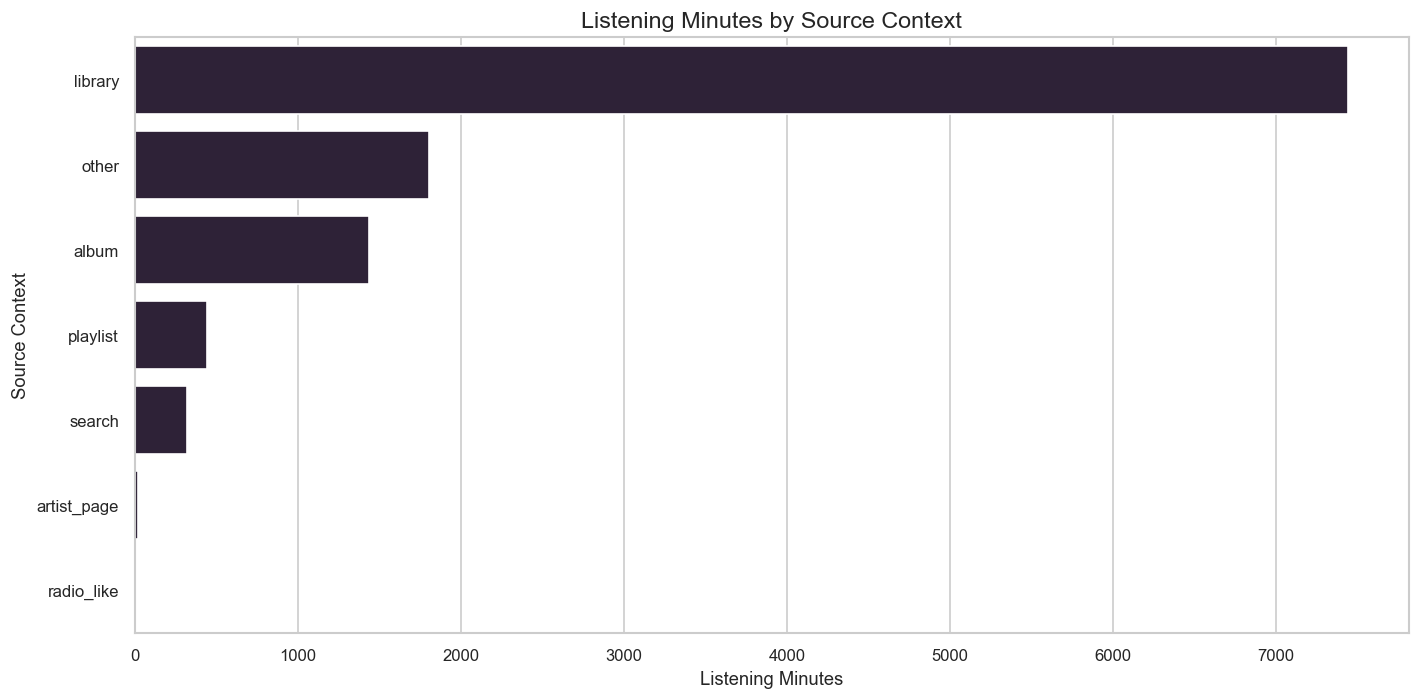

Saved Figure: /Users/Sumaitat/Documents/Coding/music-analytics/reports/figures/exploratory_data_analysis/source_context_performance.png


In [5]:
if not source_performance.empty:
    plt.figure(figsize=(12, 6))

    sns.barplot(
        data=source_performance,
        x="listening_minutes",
        y="source_context",
    )

    plt.title("Listening Minutes by Source Context")
    plt.xlabel("Listening Minutes")
    plt.ylabel("Source Context")
    plt.tight_layout()

    figure_path = save_figure("source_context_performance.png")
    plt.show()

    print("Saved Figure:", figure_path)

In [6]:
if not behavior_by_track.empty:
    features = behavior_by_track.copy()

    features = features.merge(library_flags, on="track_key", how="left")
    features = features.merge(preference_facts, on="track_key", how="left")

    if not dim_tracks.empty:
        metadata_cols = ["track_key"]

        for column in [
            "title",
            "artist",
            "album",
            "genre",
            "release_date",
            "track_duration_minutes",
            "media_duration_minutes",
            "track_duration",
        ]:
            if column in dim_tracks.columns:
                metadata_cols.append(column)

        features = features.merge(
            dim_tracks[metadata_cols].drop_duplicates("track_key"),
            on="track_key",
            how="left",
        )

    source_diversity = (
        activity_enriched
        .groupby("track_key")
        .agg(source_diversity_count=("source_context", "nunique"))
        .reset_index()
    ) if "source_context" in activity_enriched.columns else pd.DataFrame(columns=["track_key", "source_diversity_count"])

    features = features.merge(source_diversity, on="track_key", how="left")

    if "artist_name" in activity_enriched.columns:
        artist_affinity = (
            activity_enriched
            .groupby("artist_name", dropna=False)["play_minutes"]
            .sum()
            .rename("artist_total_minutes")
            .reset_index()
        )

        if "artist" in features.columns:
            features = features.merge(artist_affinity, left_on="artist", right_on="artist_name", how="left")
    else:
        features["artist_total_minutes"] = np.nan

    if "genre" in activity_enriched.columns:
        genre_affinity = (
            activity_enriched
            .groupby("genre", dropna=False)["play_minutes"]
            .sum()
            .rename("genre_total_minutes")
            .reset_index()
        )

        if "genre" in features.columns:
            features = features.merge(genre_affinity, on="genre", how="left")
    else:
        features["genre_total_minutes"] = np.nan

    max_observed = pd.to_datetime(features["last_observed"], errors="coerce", utc=True).max()
    features["recency_days"] = (max_observed - pd.to_datetime(features["last_observed"], errors="coerce", utc=True)).dt.days
    features["library_flag"] = features["library_flag"].fillna(False)
    features["favorite_flag"] = features["favorite_flag"].fillna(False)
    features["source_diversity_count"] = features["source_diversity_count"].fillna(0)

    features["explicit_preference_score"] = np.select(
        [
            features["preference_state"].astype(str).str.lower().eq("like"),
            features["preference_state"].astype(str).str.lower().eq("dislike"),
        ],
        [
            1.0,
            -1.0,
        ],
        default=0.0,
    )

    features["plays_score"] = np.log1p(features["playback_events"])
    features["minutes_score"] = np.log1p(features["total_minutes"])
    features["completion_score"] = features["mean_completion"].fillna(0).clip(0, 1)
    features["recency_score"] = 1 / (1 + features["recency_days"].fillna(features["recency_days"].max()).clip(lower=0))
    features["preliminary_affinity_score"] = (
        features["plays_score"] * 0.25
        + features["minutes_score"] * 0.25
        + features["completion_score"] * 0.20
        + features["recency_score"] * 0.10
        + features["explicit_preference_score"] * 0.15
        + features["library_flag"].astype(int) * 0.05
    )

    features = features.rename(
        columns={
            "playback_events": "total_plays",
            "total_minutes": "total_listening_minutes",
            "active_days": "unique_listening_days",
            "mean_completion": "completion_mean",
            "median_completion": "completion_median",
        }
    )

else:
    features = pd.DataFrame()

feature_summary = pd.DataFrame(
    {
        "feature_name": features.columns.tolist(),
        "non_null_count": [int(features[column].notna().sum()) for column in features.columns],
        "missing_rate": [round(features[column].isna().mean(), 4) for column in features.columns],
        "dtype": [str(features[column].dtype) for column in features.columns],
    }
) if not features.empty else pd.DataFrame()

save_table(feature_summary, "track_affinity_feature_summary.csv")
save_parquet(neutral_columns(features), "track_affinity_features.parquet")

display(features.head())
display(feature_summary)

,track_key,total_plays,total_listening_minutes,unique_listening_days,completion_mean,completion_median,short_play_rate,skip_like_rate,last_observed,library_flag,preference_state,preference_records,preference_type,favorite_flag,title,artist,album,genre,release_date,track_duration_minutes,track_duration,source_diversity_count,artist_name,artist_total_minutes,genre_total_minutes,recency_days,explicit_preference_score,plays_score,minutes_score,completion_score,recency_score,preliminary_affinity_score
0,title_artist:'round midnight,2,0.019,1,0.003,0.003,0.500,0.500,2025-10-21 15:47:03.496000+00:00,False,NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,NaT,NaN,NaN,1,NaN,"11,465.398","11,465.398",144.000,0.000,1.099,0.019,0.003,0.007,0.281
1,title_artist:'till i collapse feat nate dogg,2,0.031,1,0.006,0.006,0.500,0.500,2025-10-22 14:52:39.606000+00:00,False,NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,NaT,NaN,NaN,1,NaN,"11,465.398","11,465.398",143.000,0.000,1.099,0.030,0.006,0.007,0.284
2,title_artist:1,4,0.075,2,0.005,0.005,0.500,0.500,2025-11-09 01:10:31.236000+00:00,False,NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,NaT,NaN,NaN,1,NaN,"11,465.398","11,465.398",125.000,0.000,1.609,0.072,0.005,0.008,0.422
3,title_artist:1 shot,29,8.156,8,0.170,0.031,0.552,0.552,2026-02-05 21:46:48.031000+00:00,False,NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,NaT,NaN,NaN,3,NaN,"11,465.398","11,465.398",36.000,0.000,3.401,2.214,0.170,0.027,1.441
4,title_artist:1-800-hot-n-fun,4,1.149,2,0.199,0.199,0.250,0.250,2026-03-11 00:49:41.746000+00:00,False,NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,NaT,NaN,NaN,1,NaN,"11,465.398","11,465.398",3.000,0.000,1.609,0.765,0.199,0.250,0.658


,feature_name,non_null_count,missing_rate,dtype
0,track_key,3047,0.000,str
1,total_plays,3047,0.000,int64
2,total_listening_minutes,3047,0.000,float64
3,unique_listening_days,3047,0.000,int64
4,completion_mean,3015,0.011,float64
5,completion_median,3015,0.011,float64
6,short_play_rate,3047,0.000,float64
7,skip_like_rate,3047,0.000,float64
8,last_observed,3046,0.000,"datetime64[us, UTC]"
9,library_flag,3047,0.000,object


In [7]:
dashboard_activity = neutral_columns(activity_enriched.copy())
dashboard_listening = neutral_columns(listening.copy())
dashboard_tracks = neutral_columns(dim_tracks.copy())
dashboard_preferences = neutral_columns(preferences.copy())

source_dim = (
    source_map
    .copy()
    .rename(columns={"raw_source_context": "raw_value", "source_context": "normalized_source_context"})
) if not source_map.empty else pd.DataFrame(columns=["raw_value", "normalized_source_context", "row_count"])

if not dashboard_activity.empty:
    dashboard_activity = dashboard_activity.sort_values("event_time_local").reset_index(drop=True)

if not dashboard_listening.empty and "event_time_local" in dashboard_listening.columns:
    dashboard_listening = dashboard_listening.sort_values("event_time_local").reset_index(drop=True)

In [8]:
activity_path = save_parquet(dashboard_activity, "dashboard_play_activity_events.parquet")
listening_path = save_parquet(dashboard_listening, "dashboard_listening_events.parquet")
tracks_path = save_parquet(dashboard_tracks, "dim_tracks.parquet")
preferences_path = save_parquet(dashboard_preferences, "fact_preferences.parquet")
source_path = save_parquet(neutral_columns(source_dim), "dim_source_context.parquet")
sessions_path = save_parquet(neutral_columns(sessions), "listening_sessions.parquet")
features_path = save_parquet(neutral_columns(features), "track_affinity_features.parquet")

In [9]:
dashboard_outputs = pd.DataFrame(
    [
        {"dataset": "dashboard_play_activity_events", "path": str(activity_path.relative_to(root)), "row_count": len(dashboard_activity), "column_count": dashboard_activity.shape[1]},
        {"dataset": "dashboard_listening_events", "path": str(listening_path.relative_to(root)), "row_count": len(dashboard_listening), "column_count": dashboard_listening.shape[1]},
        {"dataset": "dim_tracks", "path": str(tracks_path.relative_to(root)), "row_count": len(dashboard_tracks), "column_count": dashboard_tracks.shape[1]},
        {"dataset": "fact_preferences", "path": str(preferences_path.relative_to(root)), "row_count": len(dashboard_preferences), "column_count": dashboard_preferences.shape[1]},
        {"dataset": "dim_source_context", "path": str(source_path.relative_to(root)), "row_count": len(source_dim), "column_count": source_dim.shape[1]},
        {"dataset": "listening_sessions", "path": str(sessions_path.relative_to(root)), "row_count": len(sessions), "column_count": sessions.shape[1]},
        {"dataset": "track_affinity_features", "path": str(features_path.relative_to(root)), "row_count": len(features), "column_count": features.shape[1]},
    ]
)

save_table(dashboard_outputs, "dashboard_dataset_outputs.csv")

display(dashboard_outputs)

,dataset,path,row_count,column_count
0,dashboard_play_activity_events,data/processed/analytics/dashboard_play_activi...,22872,82
1,dashboard_listening_events,data/processed/analytics/dashboard_listening_e...,5042,35
2,dim_tracks,data/processed/analytics/dim_tracks.parquet,10738,75
3,fact_preferences,data/processed/analytics/fact_preferences.parquet,156,20
4,dim_source_context,data/processed/analytics/dim_source_context.pa...,96,3
5,listening_sessions,data/processed/analytics/listening_sessions.pa...,491,15
6,track_affinity_features,data/processed/analytics/track_affinity_featur...,3047,32


In [10]:
metric_definition_records = metric_definitions.to_dict(orient="records")
accepted_join_records = accepted_joins.to_dict(orient="records")
rejected_join_records = rejected_joins.to_dict(orient="records")

In [11]:
handoff = {
    "project_root": str(root),
    "approved_dashboard_tables": dashboard_outputs["dataset"].tolist(),
    "approved_recommender_tables": ["track_affinity_features", "dim_tracks", "dashboard_play_activity_events", "fact_preferences"],
    "accepted_joins": accepted_join_records,
    "rejected_joins": rejected_join_records,
    "unresolved_risks": unresolved_risks,
    "metric_definitions": metric_definition_records,
    "recommended_dashboard_pages": dashboard_pages,
    "next_notebook_recommendations": next_steps,
    "eda_outputs": {
        "tables": str(eda_tables_root),
        "figures": str(eda_figures_root),
        "analytics": str(analytics_root),
    },
}

summary_path = save_json(handoff, "eda_summary.json")

NameError: name 'unresolved_risks' is not defined

In [ ]:
print("EDA Summary:", summary_path)
print(json.dumps(handoff, indent=4, default=str))

print("EDA Tables Directory:", eda_tables_root)
print("EDA Figures Directory:", eda_figures_root)
print("Analytics Directory:", analytics_root)
print("Dashboard Outputs:", eda_tables_root / "dashboard_dataset_outputs.csv")
print("EDA Summary:", eda_tables_root / "eda_summary.json")